<a href="https://colab.research.google.com/github/jrocco23/loan_default_prediction/blob/main/Capstone_Project_Reference_Notebook_Loan_Default_Prediction_Full_Code_JR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Loan Default Prediction**

## **Problem Definition**

### **The Context:**

Defaulted loans are a big problem for banks. Indeed, a lot of defaulted loans will lead to significant financial losses for banks. That's why it is important for banks to proactively identify applicants who are highly likely to default, in order to minimize risk and make more informed, profitable lending decisions.

### **The objective:**

The goal is to build a reliable predictive model based on loan history that can accurately classify prospective applicants who are likely to default, based on specific parameters, in order to automate/assist the loan approval process.

### **The key questions:**

The key questions we want to answer are:

- Which applicant characteristics (e.g., credit history, job type, debt-to-income ratio) should we focus on as the main drivers of loan default?

- How can we best balance the trade-off between catching risky loans (Recall) and accidentally rejecting good customers (Precision)?

- Which machine learning algorithm provides the best balance of accuracy and interpretability?

### **The problem formulation**:

This is a supervised binary classification problem. We are using historical tabular data of past applicants to predict a discrete, binary target variable (BAD, where 1 = Client defaulted on loan, 0 = loan repaid).

## **Data Description:**
The Home Equity dataset (HMEQ) contains baseline and loan performance information for 5,960 recent home equity loans. The target (BAD) is a binary variable that indicates whether an applicant has ultimately defaulted or has been severely delinquent. This adverse outcome occurred in 1,189 cases (20 percent). 12 input variables were registered for each applicant.


* **BAD:** 1 = Client defaulted on loan, 0 = loan repaid

* **LOAN:** Amount of loan approved.

* **MORTDUE:** Amount due on the existing mortgage.

* **VALUE:** Current value of the property.

* **REASON:** Reason for the loan request. (HomeImp = home improvement, DebtCon= debt consolidation which means taking out a new loan to pay off other liabilities and consumer debts)

* **JOB:** The type of job that loan applicant has such as manager, self, etc.

* **YOJ:** Years at present job.

* **DEROG:** Number of major derogatory reports (which indicates a serious delinquency or late payments).

* **DELINQ:** Number of delinquent credit lines (a line of credit becomes delinquent when a borrower does not make the minimum required payments 30 to 60 days past the day on which the payments were due).

* **CLAGE:** Age of the oldest credit line in months.

* **NINQ:** Number of recent credit inquiries.

* **CLNO:** Number of existing credit lines.

* **DEBTINC:** Debt-to-income ratio (all your monthly debt payments divided by your gross monthly income. This number is one way lenders measure your ability to manage the monthly payments to repay the money you plan to borrow.

## **Import the necessary libraries and Data**

In [ ]:
# libraries for data manipulation
import pandas as pd
import numpy as np

# libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.gofplots import ProbPlot

# library for building logistic regression models
from sklearn.linear_model import LogisticRegression

# library for preparing the data
from sklearn.model_selection import train_test_split

# libraries for evaluating the model
from sklearn import metrics
from sklearn.metrics import confusion_matrix, classification_report,accuracy_score,precision_score,recall_score,f1_score

# libraries for working with decision tree models
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier

# ensemble learning methods
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import RandomForestClassifier

# library for statistical analysis
import scipy.stats as stats

# library for hyperparameter tuning
from sklearn.model_selection import GridSearchCV

# library to ignore warnings
import warnings
warnings.filterwarnings("ignore")

## **Data Overview**

- Reading the dataset
- Understanding the shape of the dataset
- Checking the data types
- Checking for missing values
- Checking for duplicated values

In [ ]:
# read the data
df = pd.read_csv('hmeq.csv')

In [ ]:
# return the first 5 rows from the data
df.head()

,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
0,1,1100,25860.0,39025.0,HomeImp,Other,10.5,0.0,0.0,94.366667,1.0,9.0,NaN
1,1,1300,70053.0,68400.0,HomeImp,Other,7.0,0.0,2.0,121.833333,0.0,14.0,NaN
2,1,1500,13500.0,16700.0,HomeImp,Other,4.0,0.0,0.0,149.466667,1.0,10.0,NaN
3,1,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,1700,97800.0,112000.0,HomeImp,Office,3.0,0.0,0.0,93.333333,0.0,14.0,NaN


In [ ]:
# check number of rows (loans) and number of columns (attributes of the loan/applicants associated to each loan) in our data
print("There are", df.shape[0], 'rows and', df.shape[1], "columns in the data.")

There are 5960 rows and 13 columns in the data.


#### Observations:

The DataFrame has 13 columns as also shown from the Attribute Information above. Data in each row corresponds to a specific house equity loan. 5960 rows are present in the data. We can conclude that the dataset has been uploaded properly.

In [ ]:
# check if all data types make sense for the data attributes we are working on
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5960 entries, 0 to 5959
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   BAD      5960 non-null   int64  
 1   LOAN     5960 non-null   int64  
 2   MORTDUE  5442 non-null   float64
 3   VALUE    5848 non-null   float64
 4   REASON   5708 non-null   object 
 5   JOB      5681 non-null   object 
 6   YOJ      5445 non-null   float64
 7   DEROG    5252 non-null   float64
 8   DELINQ   5380 non-null   float64
 9   CLAGE    5652 non-null   float64
 10  NINQ     5450 non-null   float64
 11  CLNO     5738 non-null   float64
 12  DEBTINC  4693 non-null   float64
dtypes: float64(9), int64(2), object(2)
memory usage: 605.4+ KB


In [ ]:
# Analyse missing values
df.isnull().sum()

,0
BAD,0
LOAN,0
MORTDUE,518
VALUE,112
REASON,252
JOB,279
YOJ,515
DEROG,708
DELINQ,580
CLAGE,308


In [ ]:
# Check the percentage of missing values in the each column.
# we divide the result from the previous code by the number of rows in the dataset
(df.isnull().sum() / len(df)) * 100

,0
BAD,0.000000
LOAN,0.000000
MORTDUE,8.691275
VALUE,1.879195
REASON,4.228188
JOB,4.681208
YOJ,8.640940
DEROG,11.879195
DELINQ,9.731544
CLAGE,5.167785


#### Observations:

- We can see that only for the attributes BAD and LOAN there are no missing values. For all the other attributes, we have some missing values, with DEBTINC having the highest amount of missing values (about 21% of all the observations related to DEBTINC).
- 11 out of 13 columns are numeric, while REASON and JOB are string.
- Looking at the percentages of missing values for every column, we see that 7 of them are over 5%. It is better in this case to fill the missing values. As a simple imputation method, we can fill the missing values with median and mode.

Since the variable BAD is in reality categorical, it is better to transform it. Or better, we can just convert the object type columns to categories (since this reduces the data space required to store the dataframe) and then add to this categories list the target variable BAD, as this is an classification problem.

In [ ]:
cols = df.select_dtypes(['object']).columns.tolist()

# add target variable BAD to the cols list
cols.append('BAD')

# print the list
cols

['REASON', 'JOB', 'BAD']

In [ ]:
# change the data type of object type column to category.

for i in cols:
    df[i] = df[i].astype('category')

In [ ]:
# Check the info again
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5960 entries, 0 to 5959
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   BAD      5960 non-null   category
 1   LOAN     5960 non-null   int64   
 2   MORTDUE  5442 non-null   float64 
 3   VALUE    5848 non-null   float64 
 4   REASON   5708 non-null   category
 5   JOB      5681 non-null   category
 6   YOJ      5445 non-null   float64 
 7   DEROG    5252 non-null   float64 
 8   DELINQ   5380 non-null   float64 
 9   CLAGE    5652 non-null   float64 
 10  NINQ     5450 non-null   float64 
 11  CLNO     5738 non-null   float64 
 12  DEBTINC  4693 non-null   float64 
dtypes: category(3), float64(9), int64(1)
memory usage: 483.7 KB


In [ ]:
# as a last sanity check, we want to be sure there are no duplicates in the data
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
5955,False
5956,False
5957,False
5958,False


There are no duplicates in the data. All the rows are unique.


## Summary Statistics

In [ ]:
# select only the numerical columns
num_cols = df.select_dtypes('number').columns

# summary statistics
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
LOAN,5960.0,18607.969799,11207.480417,1100.000000,11100.000000,16300.000000,23300.000000,89900.000000
MORTDUE,5442.0,73760.817200,44457.609458,2063.000000,46276.000000,65019.000000,91488.000000,399550.000000
VALUE,5848.0,101776.048741,57385.775334,8000.000000,66075.500000,89235.500000,119824.250000,855909.000000
YOJ,5445.0,8.922268,7.573982,0.000000,3.000000,7.000000,13.000000,41.000000
DEROG,5252.0,0.254570,0.846047,0.000000,0.000000,0.000000,0.000000,10.000000
DELINQ,5380.0,0.449442,1.127266,0.000000,0.000000,0.000000,0.000000,15.000000
CLAGE,5652.0,179.766275,85.810092,0.000000,115.116702,173.466667,231.562278,1168.233561
NINQ,5450.0,1.186055,1.728675,0.000000,0.000000,1.000000,2.000000,17.000000
CLNO,5738.0,21.296096,10.138933,0.000000,15.000000,20.000000,26.000000,71.000000
DEBTINC,4693.0,33.779915,8.601746,0.524499,29.140031,34.818262,39.003141,203.312149


#### Some observations:

- All the numerical columns expect LOAN have missing values. Indeed, by looking at the count column, we can see that LOAN has 5,960 rows, that is the total number of rows. Every other column has fewer than 5,960 rows, meaning all other features contain missing values. DEBTINC is missing the most data, with only 4,693 non-null entries (about 21% of its data is missing).

- For both DEROG and DELINQ, the 25%, 50% (median), and 75% percentiles are exactly 0. This means that at least 75% of the applicants have a perfectly clean history in these areas. However, their maximum values are 10 and 15, respectively, indicating a heavy right skew with a few highly risky applicants.

- DEBTINC (Debt-to-Income ratio) has a maximum value of 203.31. A debt-to-income ratio of over 200% is extremely abnormal and could indicate a data entry error or a massive outlier.

- CLAGE (Age of the oldest credit line in months) has a maximum value of 1,168. But 1,168 months equals over 97 years. This is mostly likely to be a data entry error.

- VALUE and MORTDUE both show huge jumps between their 75th percentiles and their maximum values, indicating a few very expensive outlier properties.

## **Exploratory Data Analysis (EDA) and Visualization**

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Leading Questions**:
1. What is the range of values for the loan amount variable "LOAN"?
2. How does the distribution of years at present job "YOJ" vary across the dataset?
3. How many unique categories are there in the REASON variable?
4. What is the most common category in the JOB variable?
5. Is there a relationship between the REASON variable and the proportion of applicants who defaulted on their loan?
6. Do applicants who default have a significantly different loan amount compared to those who repay their loan?
7. Is there a correlation between the value of the property and the loan default rate?
8. Do applicants who default have a significantly different mortgage amount compared to those who repay their loan?

### **Univariate Analysis**


Firs we start by analysing the numerical variables, through histograms and boxplots.

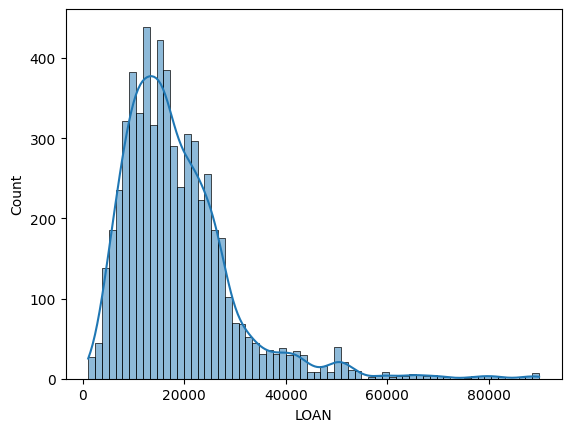

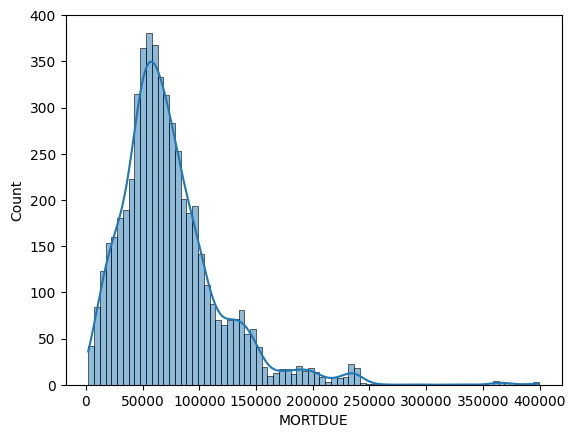

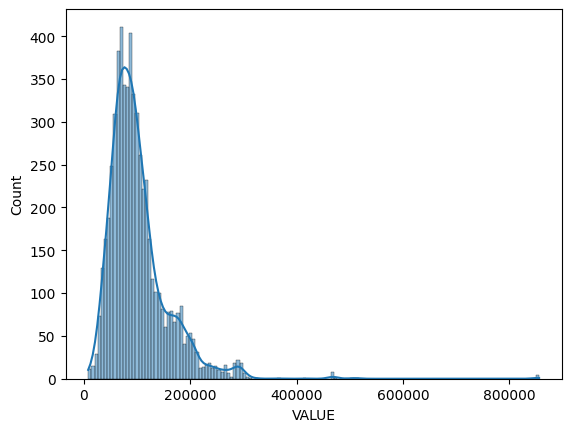

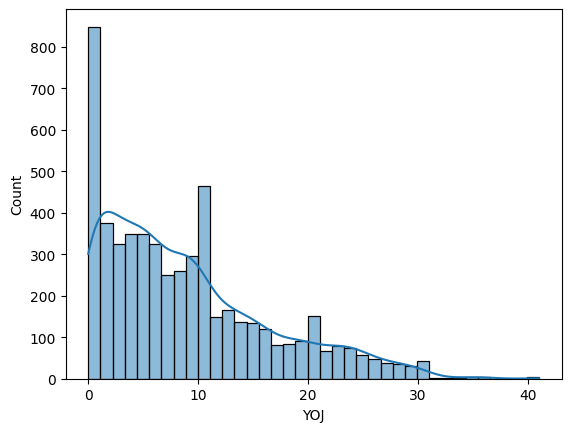

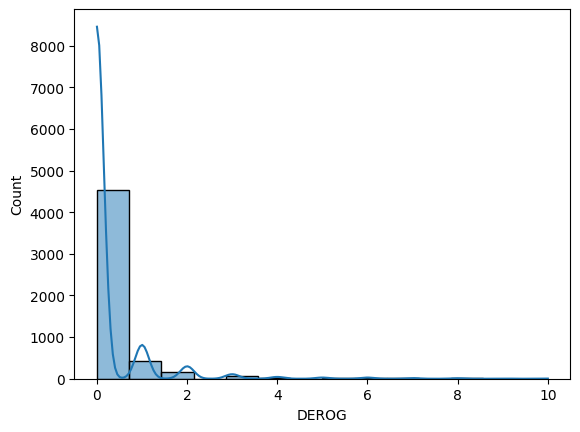

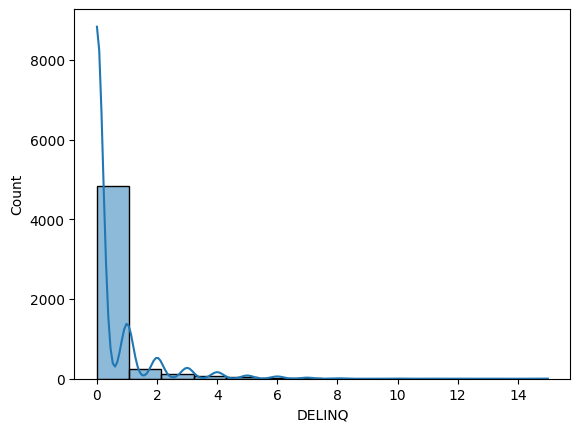

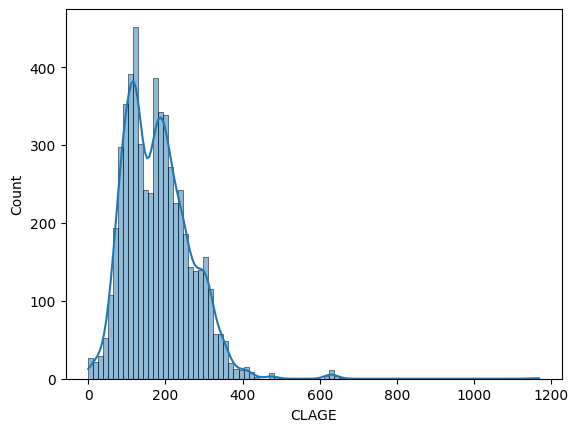

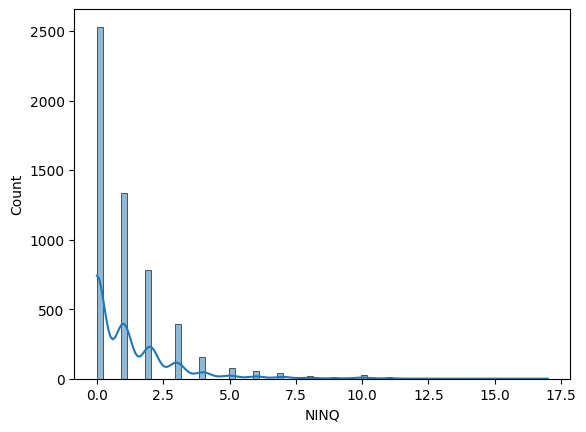

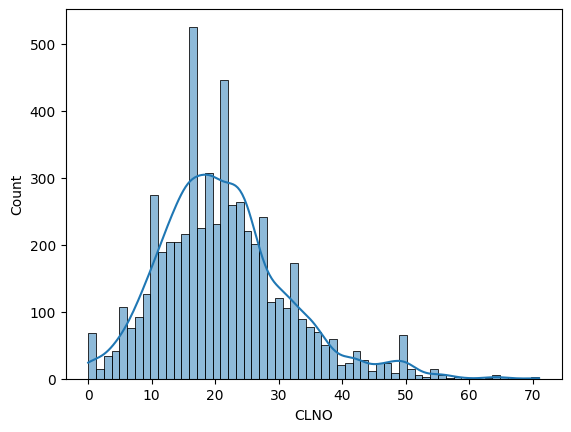

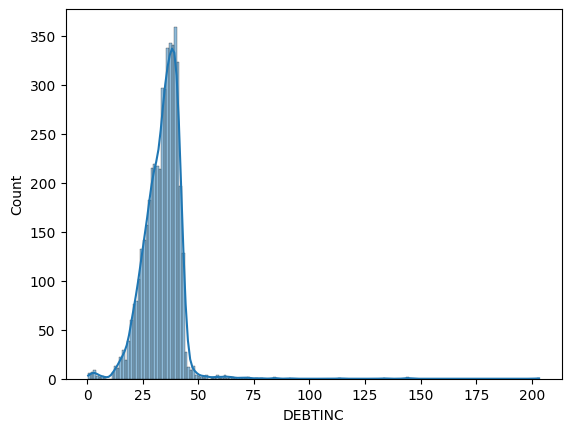

In [ ]:
# let's plot all the numerical columns in order to see their distributions
# we start first with the histograms

for i in df[num_cols]:

    plt.figure()
    sns.histplot(data = df, x = i, kde = True)
    plt.show()

#### Observations:

- Looking at the variable LOAN, we can see that we have a wide range of values. As seen from the summary statistics, this range goes from a value of 1100 to 89900. As shown from the histogram, the distribution is skewed to the right (positively skewed). We expect to see a boxplot with median < mean, a right whisker longer than the left one, and the presence of many outliers with high values of LOAN.
- Looking at the variable YOJ, which represents the number of years spent working for the current job, the histogram shows a clear downward trend. When the number of years increases, the number of observations in each cluster decreases. This results makes sense for a number of reasons. For example, we can expect that people working more than 20 years for the current job are "old enough" to have saved enough money, as well as they do not need to finance any major project at this stage of their lives (houses, cars, and so on).
- Considering all the other variables, we notice how the majority of loans have neen repaid (so BAD = 0).

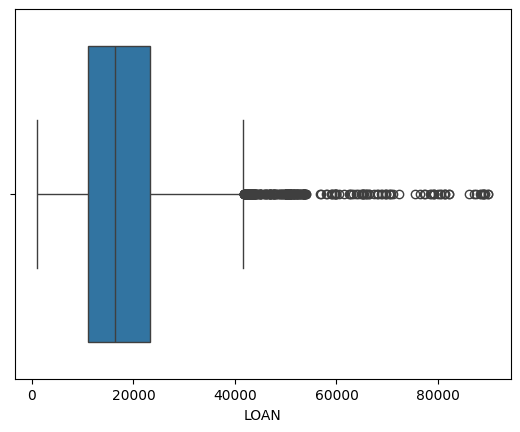

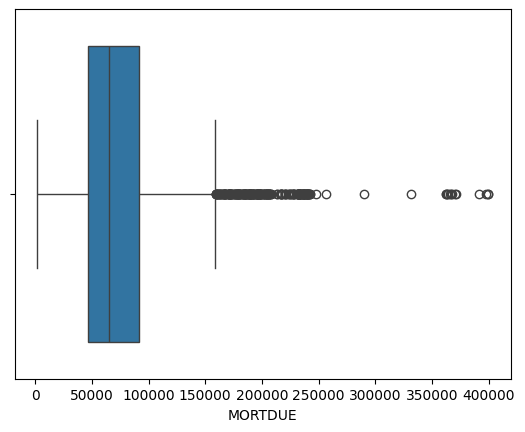

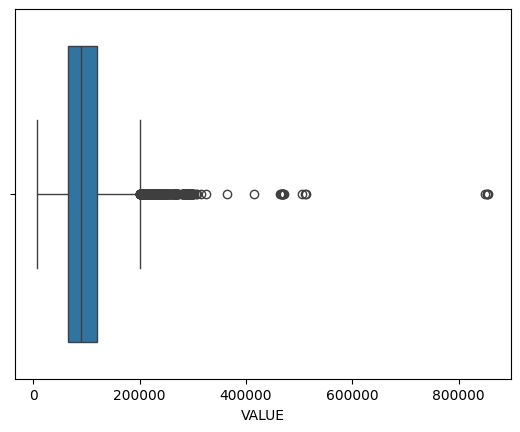

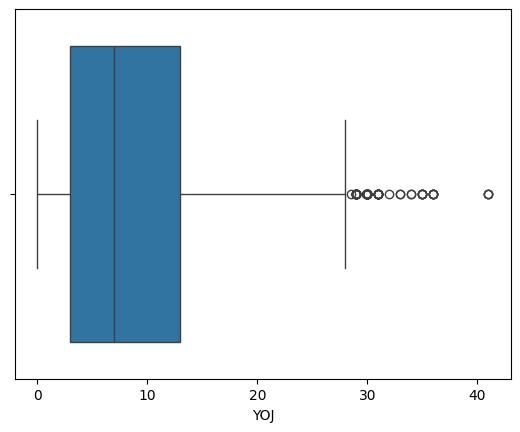

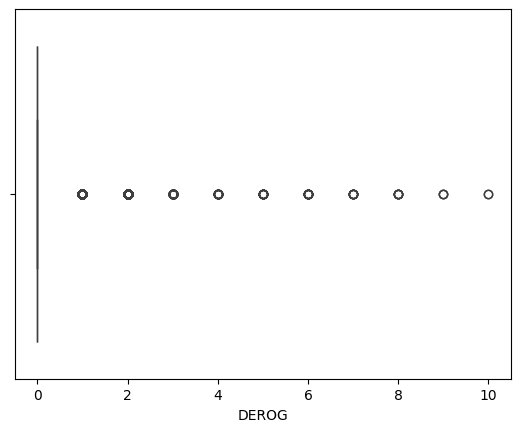

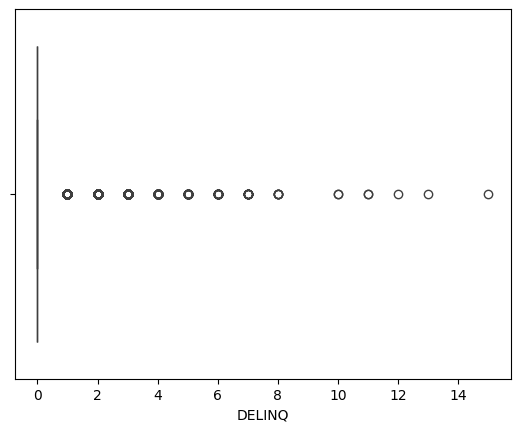

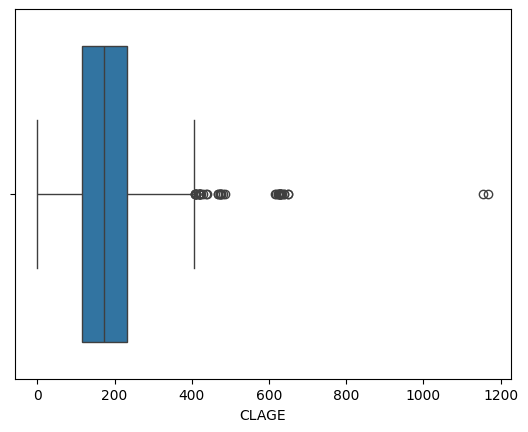

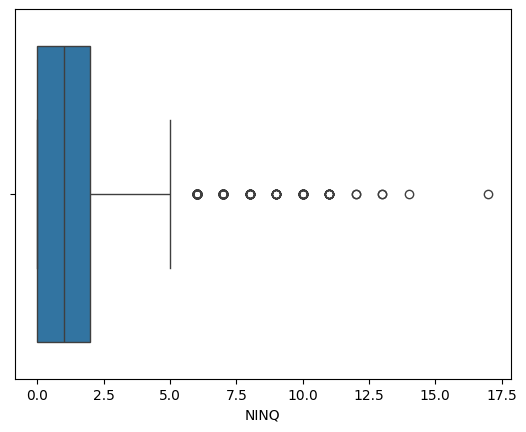

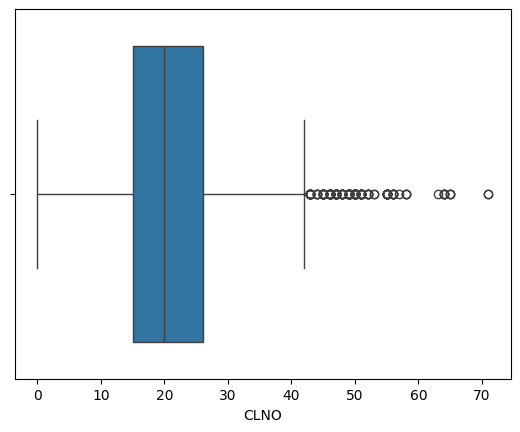

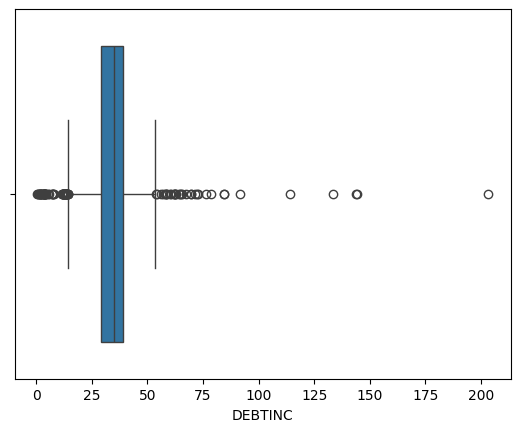

In [ ]:
# boxplots of all the numerical attributes

for i in df[num_cols]:

    plt.figure()
    sns.boxplot(data = df, x = i)
    plt.show()

From the boxplots, we can see how all the variables present outliers, in particular outliers with high values, with DEBTINC that also show outliers with low values.

Let's now look at the categorical variables: REASON AND JOB.

In [ ]:
cat_cols = ['BAD', 'REASON', 'JOB']

# print the number of occurrences of each unique value in each categorical column
for col in cat_cols:
    print(df[col].value_counts(normalize = True))  # setting parameter normalize = True gives us the percentage of each category
    print('*'*40)

BAD
0    0.800503
1    0.199497
Name: proportion, dtype: float64
****************************************
REASON
DebtCon    0.688157
HomeImp    0.311843
Name: proportion, dtype: float64
****************************************
JOB
Other      0.420349
ProfExe    0.224608
Office     0.166872
Mgr        0.135011
Self       0.033973
Sales      0.019187
Name: proportion, dtype: float64
****************************************


- We can see that there are two unique categories for the variable REASON, which are Debtcon (debt consolidation) and HomeImp (home improvement). We notice that debt consolidation is the major reason for taking a loan, with almost 69% of the loans reporting this reason.
- For the variable JOB, we see that the most common category is Other, which groups several different roles together. Apart from this, the second most common category is ProfExe.

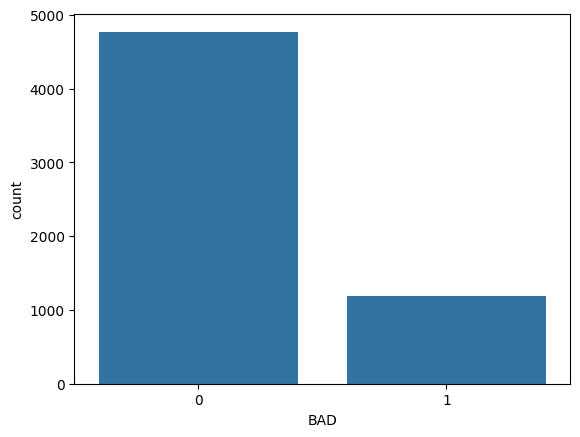

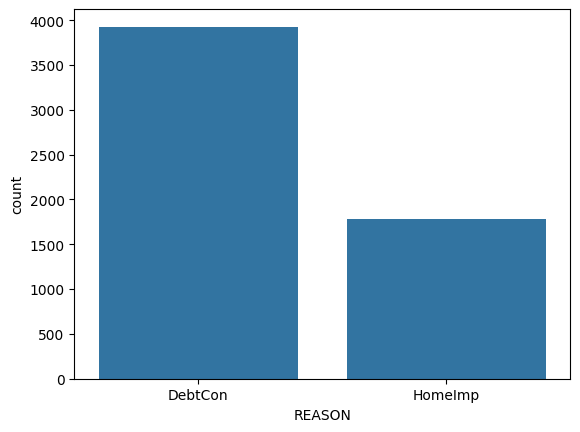

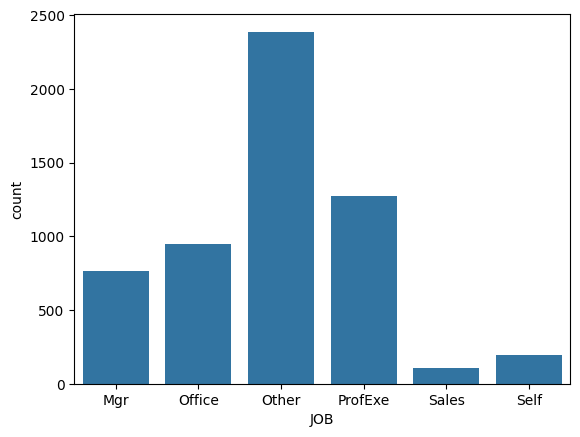

In [ ]:
# barcharts for the categorical variables REASON AND JOB

for i in df[cat_cols]:

    plt.figure()
    sns.countplot(data=df, x=i)
    plt.show()

### **Bivariate Analysis**

Now let's look at the relationships between different pairs of numerical and categorical variables.

First, we want to see if there is any relationship between the reason of the loan request, and the proportion of applicants who defaulted on their loan. So we want to discover whatever reason is more associated to the risk of loan default. To visualize this, we can use a barchart.

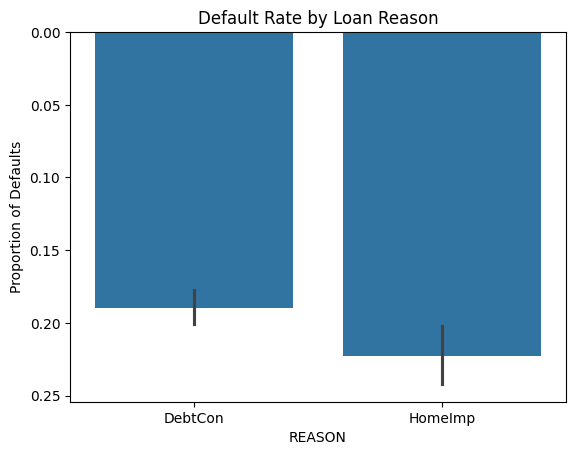

In [ ]:
# relationship between REASON and BAD

sns.barplot(x="REASON", y="BAD", data=df)
plt.title("Default Rate by Loan Reason")
plt.ylabel("Proportion of Defaults")
plt.show()

In [ ]:
pd.crosstab(df["REASON"], df["BAD"], normalize="index")

BAD,0,1
REASON,,
DebtCon,0.810336,0.189664
HomeImp,0.777528,0.222472


We can see that higher defaults are associated with loans whose reason is HomeImp (so home improvements).

Now we want to know if applicants who default (BAD = 0) have a significantly different loan amount compared to those who repay their loan.

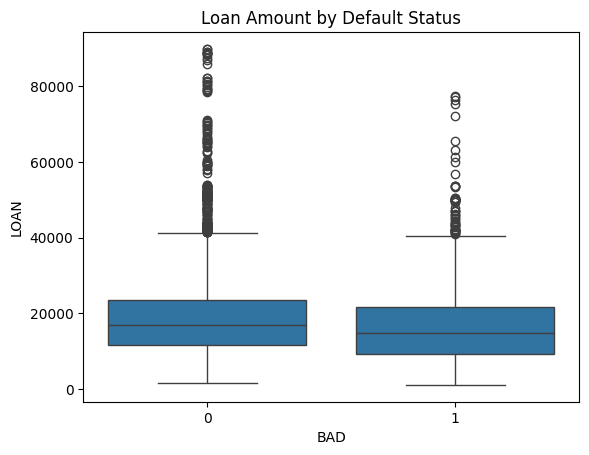

In [ ]:
# boxplot showing the distribution of the loan amount by default status

sns.boxplot(x="BAD", y="LOAN", data=df)
plt.title("Loan Amount by Default Status")
plt.show()

Next, we want to evaluate if there is a correlation between the value of the property (VALUE) and the loan default rate (BAD). To do this, we are going to use again a boxplot.

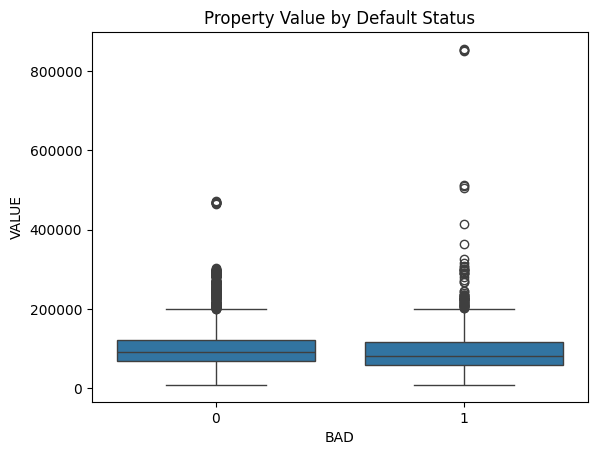

In [ ]:
sns.boxplot(x="BAD", y="VALUE", data=df)
plt.title("Property Value by Default Status")
plt.show()

Finally, we want to see if applicants who default (BAD) have a significantly different mortgage amount (MORTDUE) compared to those who repay their loan.

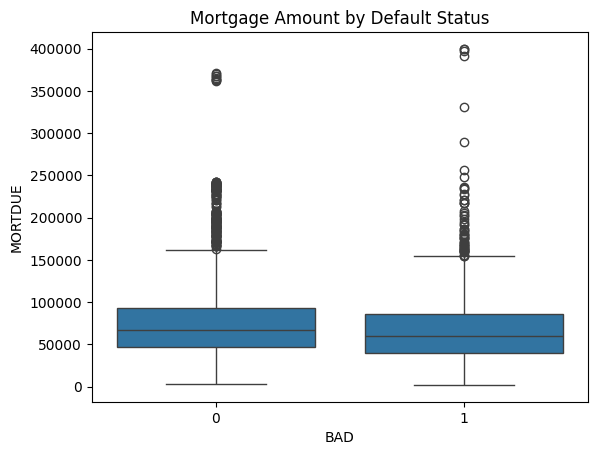

In [ ]:
sns.boxplot(x="BAD", y="MORTDUE", data=df)
plt.title("Mortgage Amount by Default Status")
plt.show()

### **Multivariate Analysis**

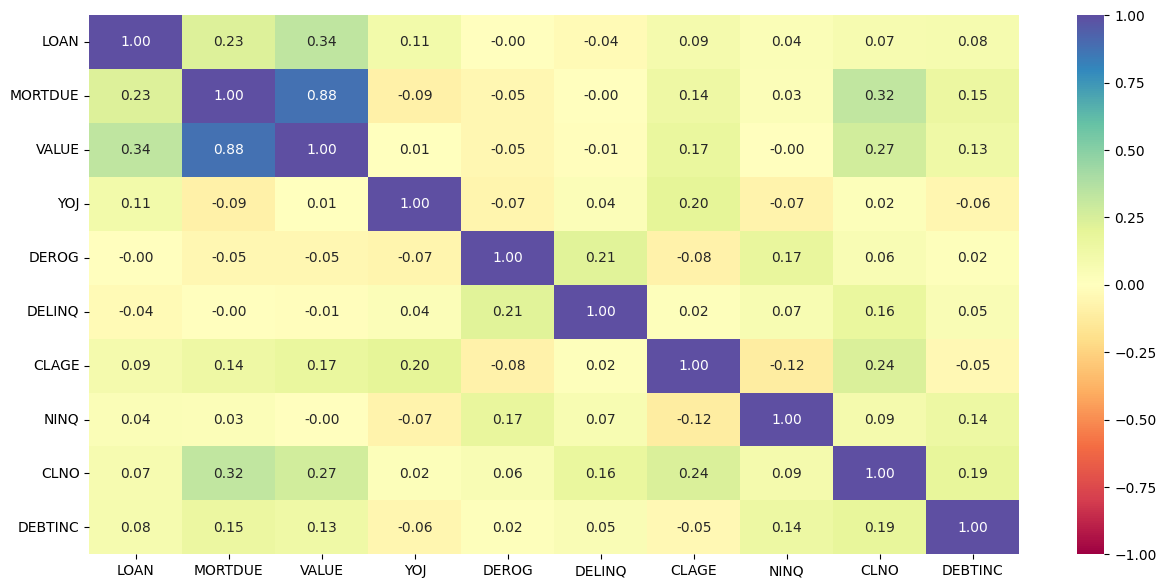

In [ ]:
# we want to explore the relationships between all the numerical variables

# we can create a heatmap considering all the numerical variables
plt.figure(figsize=(15, 7))
sns.heatmap(df[num_cols].corr(), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral")
plt.show()

As we can see from the heatmap, the only attributes having significant correlation (|coeff| >= 0.7) are
VALUE and MORTDUE. The correlation between the two variables is positive. Of course this makes sense, as we expect higher amounts due on the existing mortgages for more expensive properties.

## Treating Outliers

In [ ]:
def treat_outliers(df, col):
    '''
    treats outliers in a variable
    col: str, name of the numerical variable
    df: data frame
    col: name of the column
    '''

    Q1 = df[col].quantile(0.25)   # 25th quantile
    Q3 = df[col].quantile(0.75)   # 75th quantile
    IQR = Q3 - Q1                 # IQR Range
    Lower_Whisker = Q1 - 1.5 * IQR  # define lower whisker
    Upper_Whisker = Q3 + 1.5 * IQR  # define upper Whisker

    # all the values smaller than Lower_Whisker will be assigned value of Lower_whisker
    # and all the values above upper_whishker will be assigned value of upper_Whisker
    df[col] = np.clip(df[col], Lower_Whisker, Upper_Whisker)

    return df

def treat_outliers_all(df, col_list):
    '''
    treat outlier in all numerical variables
    col_list: list of numerical variables
    df: data frame
    '''
    for c in col_list:
        df = treat_outliers(df, c)

    return df

In [ ]:
df_raw = df.copy()

numerical_col = df_raw.select_dtypes(include=np.number).columns.tolist() # get the list of numerical columns

df = treat_outliers_all(df_raw,numerical_col)

## Treating Missing Values

As mentioned the Data Overview section 11 out of 13 variables have missing values. We now proceed in treating these missing values. In order to do that, we add new columns in the dataset for each column which has missing values.

In [ ]:
# For each column we create a binary flag for the row. It is going to be 1 if there is a missing value in the row, otherwise it will be 0.
def add_binary_flag(df,col):
    '''
    df: It is the dataframe
    col: it is column which has missing values
    It returns a dataframe which has a binary for missing values in column col
    '''
    new_col = str(col)
    new_col += '_missing_values_flag'
    df[new_col] = df[col].isna()
    return df

In [ ]:
# list of columns that has missing values in it
missing_col = [col for col in df.columns if df[col].isnull().any()]

for colmn in missing_col:
    add_binary_flag(df,colmn)

Now we will fill the missing values in numerical columns with the median, and the missing values in the categorical variables with the mode.

In [ ]:
# Select numeric columns
num_data = df.select_dtypes('number')

# Select category columns
cat_data = df.select_dtypes('category').columns.tolist()

# Fill numeric columns with median.
df[num_data.columns] = num_data.fillna(num_data.median())

# Fill categoric columns with mode.
for column in cat_data:
    mode = df[column].mode()[0]
    df[column] = df[column].fillna(mode)

## **Important Insights from EDA**

What are the the most important observations and insights from the data based on the EDA performed?

- Most variables contain missing values, especially DEBTINC, making data imputation (data filling) an important step.
- The majority of loans are non-defaults (BAD = 0), indicating class imbalance in the dataset.
- Variables like LOAN, YOJ, DELINQ, and DEROG are right-skewed, with most values concentrated at lower ranges and a few extreme observations.
- Extreme values in variables like DEBTINC, CLAGE, VALUE, and MORTDUE suggest outliers or possible data inconsistencies.
- It is interesting to note that most applicants have zero delinquencies and derogatory reports, indicating that the risk is concentrated in a smaller subset of applicants.

## **Model Building - Approach**
- Data preparation
- Partition the data into train and test set
- Build the model
- Fit on the train data
- Tune the model
- Test the model on test set

In the first part we are going to prepare the data, this means we'll first split the dataset df in 2 parts: one part containing the observations related to the dependent variable, the other containing all the indipendent variables. Then, we'll split it again into train and test set, in a ratio of 70:30 for train and test set.

Since our goal is to predict "bad" loans, so the ones for which BAD = 1, it makes sense in this case to use a 70:30 ratio instead of a 80:20. This because the observations with BAD = 1 represent the minority class (they are just about 20% of all the observations for the variable BAD), and so we want to work with a bigger test set. This will ensure a much more reliable measure of how well the model actually detects bad loans.

In [ ]:
# create two datasets separating the dependent variable (target variable BAD) and indepedent variables
Y = df['BAD']
X = df.drop(columns = ['BAD'])

# create dummy variables for the categorical variables
dummies_cols = ['REASON', 'JOB']
X = pd.get_dummies(data = X, columns = dummies_cols, drop_first = True)

# split the data in 70:30 ratio of train to test data
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.30 , random_state=1)

In [ ]:
# check the shape of the train and test data
print("Shape of Training set : ", X_train.shape)
print("Shape of test set : ", X_test.shape)

Shape of Training set :  (4172, 27)
Shape of test set :  (1788, 27)


As seen from the EDA section, our target variable BAD is heavily imbalanced. We have indeed about 80% of loans that have been repaid, and 20% not. In this case, it is better to proceed using the Stratified Sampling technique. Doing this, we are sure that both the training and the test sets obtained by the splitting procedure will have the same percentage of loans that have been repaid (80%) and loans that have not been repaid (20%).

In [ ]:
# split the data in 70:30 ratio of train to test data, but using now the Stratified Sampling technique
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.30, random_state=1, stratify=Y)

Now, in order to evaluate the regression models we are going to build, we need to create a function that will print out a report showing the main classification metrics: Precision, Recall, F1-Score, and Accuracy for both class 0 and class 1. We will consider any observation in class 0 as 'Paid' (loan paid), and any observation in class 1 as 'Defaulted' (the applicant defaulted on the loan).  

In [ ]:
# create metric function
def metrics_score(actual, predicted):
    print(classification_report(actual, predicted))
    cm = confusion_matrix(actual, predicted)
    plt.figure(figsize=(8,5))
    sns.heatmap(cm, annot=True,  fmt='.2f', xticklabels=['Paid', 'Default'], yticklabels=['Paid', 'Default'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()

### Logistic Regression

In [ ]:
# create the logistic regression model
lr = LogisticRegression(random_state=1)

# fit the model on the train data
lr.fit(X_train,y_train)

LogisticRegression(random_state=1)

Now we need to check the performance of this model on the train and test sets.

              precision    recall  f1-score   support

           0       0.80      1.00      0.89      3340
           1       0.52      0.02      0.04       832

    accuracy                           0.80      4172
   macro avg       0.66      0.51      0.46      4172
weighted avg       0.75      0.80      0.72      4172



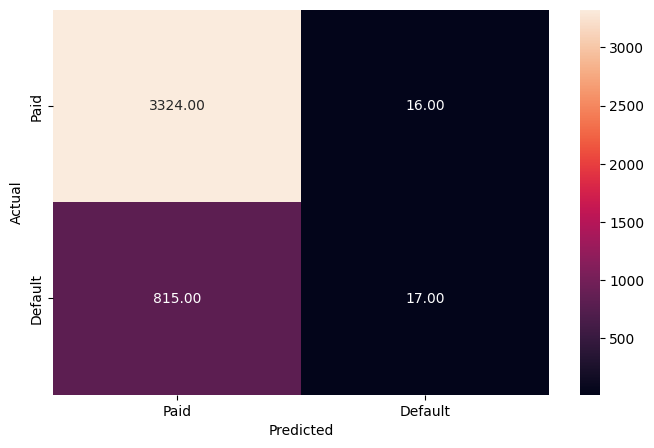

In [ ]:
# predictions for the train set
y_pred_train = lr.predict(X_train)

# check the performance on the train set
metrics_score(y_train, y_pred_train)

              precision    recall  f1-score   support

           0       0.81      1.00      0.89      1431
           1       0.71      0.03      0.06       357

    accuracy                           0.80      1788
   macro avg       0.76      0.52      0.48      1788
weighted avg       0.79      0.80      0.73      1788



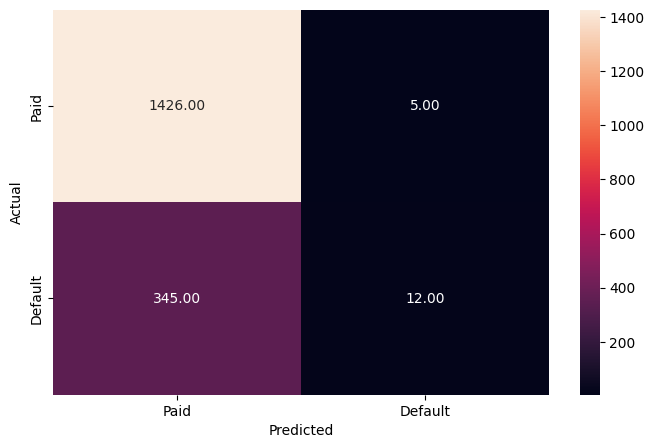

In [ ]:
# predictions for the test set
y_pred_test = lr.predict(X_test)

# check the performance on the test set
metrics_score(y_test, y_pred_test)

Looking at the accuracy score, it is the same for both the train and test sets (81%). This means that the model is stable and not overfitting. The problem is that we have a low recall. The model can successfully catch a few amounts of people who actually defaulted. If a bank used this model, it would approved many loans that in reality are going to default. So this is not ideal. Finally, we can at least say that the test precision is quite high (72% in the test set).

Now we are going to check the coefficients, and also check which variables are more important and how they affect the process of loan approval.

In [ ]:
# print the coefficients of the logistic regression

# combine the coefficients and the intercept into a single DataFrame
coef_df = pd.DataFrame(
    np.append(lr.coef_, lr.intercept_),
    index=X_train.columns.tolist() + ['Intercept'],
    columns=['Coefficients']
)

print(coef_df)

                             Coefficients
LOAN                            -0.000026
MORTDUE                         -0.000007
VALUE                            0.000001
YOJ                             -0.034806
DEROG                            0.000000
DELINQ                           0.000000
CLAGE                           -0.006660
NINQ                             0.024695
CLNO                             0.003025
DEBTINC                          0.023146
MORTDUE_missing_values_flag      0.000379
VALUE_missing_values_flag        0.005410
REASON_missing_values_flag      -0.000151
JOB_missing_values_flag         -0.002581
YOJ_missing_values_flag         -0.002673
DEROG_missing_values_flag       -0.004126
DELINQ_missing_values_flag      -0.003533
CLAGE_missing_values_flag        0.000921
NINQ_missing_values_flag        -0.002622
CLNO_missing_values_flag         0.000241
DEBTINC_missing_values_flag      0.033579
REASON_HomeImp                   0.001523
JOB_Office                      -0

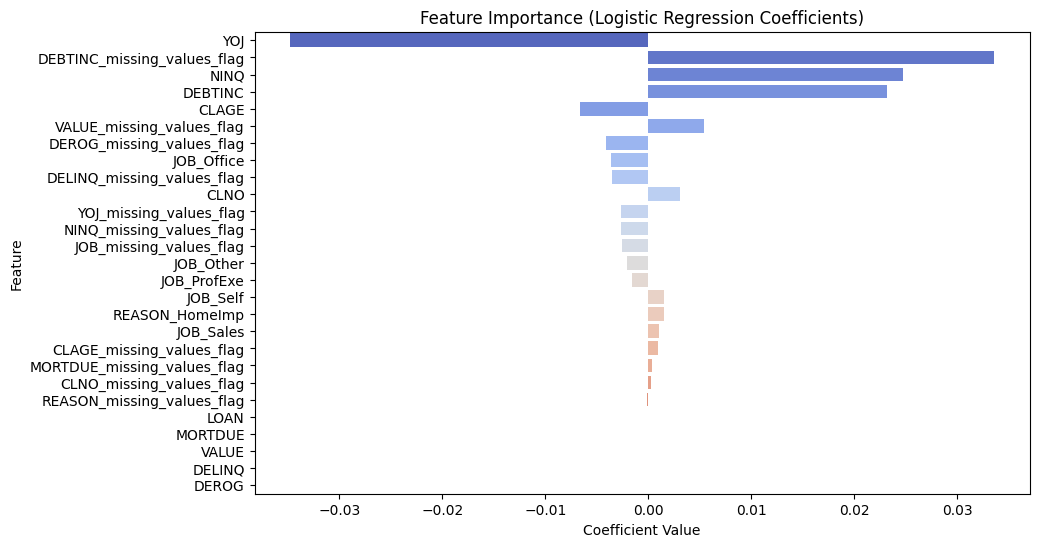

In [ ]:
# sort the coefficients by their absolute values to see which are most important
coef_df['Abs_Coefficients'] = coef_df['Coefficients'].abs()
sorted_coef = coef_df.sort_values(by='Abs_Coefficients', ascending=False).drop('Intercept', errors='ignore')

# plot the feature importance
plt.figure(figsize=(10, 6))
sns.barplot(x=sorted_coef['Coefficients'], y=sorted_coef.index, palette='coolwarm')
plt.title('Feature Importance (Logistic Regression Coefficients)')
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
plt.show()

#### Observations:

- Variables indicating poor past credit behavior, specifically DELINQ (number of delinquent credit lines), NINQ (number of recent credit inquiries) and DEROG (number of major derogatory reports), have high positive coefficients and significantly increase the risk of default.
- YOJ has the largest negative coefficient, indicating that the longer an applicant has been at their current job, the significantly less likely they are to default on their loan.

We know that the above Logistic regression model was built on the threshold of 0.5, because by default the predict() function uses this value. We can surely use another threshold, in particulare the optimal threshold. To find it, we can rely on the ROC curve and, even better, the Precision-Recall curve. From this curve we can see how the values of Precision and Recall change based on a set threshold. For a bank, missing a default is usually much more expensive than accidentally rejecting a good customer. Therefore, banks generally prefer to lower the threshold to maximize Recall, even if it impacts a little bit on Precision and Accuracy.

Optimal Threshold based on ROC curve: 0.2128



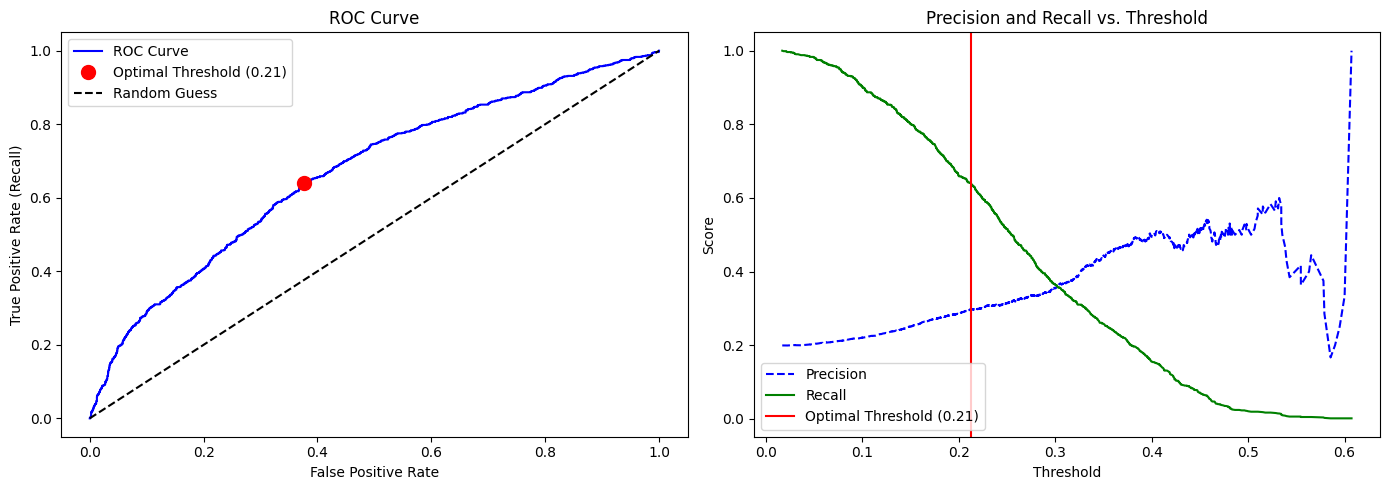

Performance on Test Set with OPTIMAL Threshold
              precision    recall  f1-score   support

           0       0.87      0.61      0.72      1431
           1       0.29      0.63      0.40       357

    accuracy                           0.62      1788
   macro avg       0.58      0.62      0.56      1788
weighted avg       0.75      0.62      0.65      1788



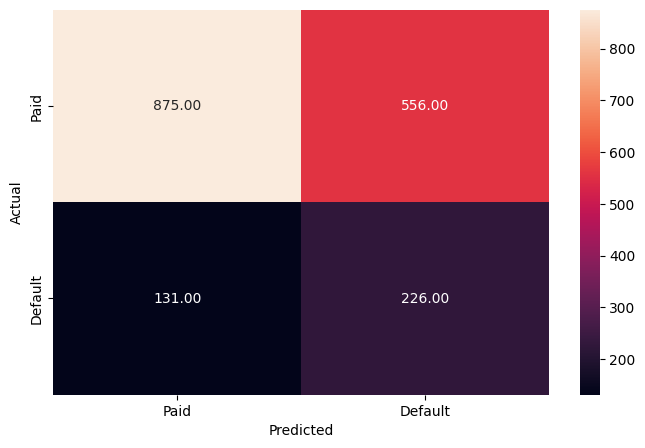

In [ ]:
from sklearn.metrics import roc_curve, precision_recall_curve

# get predicted probabilities for the positive class (1 = Default)
# predict_proba returns two columns: [prob_class_0, prob_class_1]. We want the second column.
y_pred_proba_train = lr.predict_proba(X_train)[:, 1]
y_pred_proba_test = lr.predict_proba(X_test)[:, 1]

# we want to find the optimal treshold
# calculate False Positive Rate (fpr), True Positive Rate (tpr/recall), and thresholds
fpr, tpr, thresholds = roc_curve(y_train, y_pred_proba_train)

# the optimal threshold maximizes the True Positive Rate while minimizing the False Positive Rate.
# this is calculated using Youden's Index: max(TPR - FPR)
optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]

print(f"Optimal Threshold based on ROC curve: {optimal_threshold:.4f}\n")

# plot the ROC Curve
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, label='ROC Curve', color='blue')
plt.plot(fpr[optimal_idx], tpr[optimal_idx], 'ro', markersize=10,
         label=f'Optimal Threshold ({optimal_threshold:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess') # Diagonal line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve')
plt.legend()

# calculate precision and recall for every possible threshold
precisions, recalls, pr_thresholds = precision_recall_curve(y_train, y_pred_proba_train)

# plot Precision and Recall vs. Threshold
plt.subplot(1, 2, 2)
plt.plot(pr_thresholds, precisions[:-1], 'b--', label='Precision')
plt.plot(pr_thresholds, recalls[:-1], 'g-', label='Recall')
plt.axvline(x=optimal_threshold, color='red', linestyle='-',
            label=f'Optimal Threshold ({optimal_threshold:.2f})')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs. Threshold')
plt.legend()

plt.tight_layout()
plt.show()

# apply the new optimal threshold to the test set predictions
# if probability >= optimal_threshold, classify as 1. Else, classify as 0.
y_pred_test_optimal = (y_pred_proba_test >= optimal_threshold).astype(int)

print("Performance on Test Set with OPTIMAL Threshold")
# using the custom metric function you defined earlier
metrics_score(y_test, y_pred_test_optimal)

Now we can see that, using the optimal threshold, the model is catching 62% of the defaults (recall = 0.62). There is of course a trade off: we loose precision, which drops to 31%. The overall accuracy dropped as well to 65%, but this is not bad in reality because this model is surely more useful than the one before.

### Decision Tree

Treating tree based models, now we do not need to treat potential outliers. That's because we do not care about how high a value is, we just use binary rules to split the data into regions.

In [ ]:
# drop the dependent variable from df and create the X(independent variable) matrix
X = df.drop('BAD', axis=1)

# create dummy variables for the categorical variables
X = pd.get_dummies(X, drop_first=True)

# create y(dependent variable)
y = df['BAD']

In [ ]:
# split the data into training and test set (with stratify = Y because the data is unbalanced)
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size = 0.3, random_state = 1, stratify = Y)

In [ ]:
# define the Decision tree model with class weights class_weight={0: 0.2, 1: 0.8}
dt = DecisionTreeClassifier(class_weight = {0: 0.2, 1: 0.8}, random_state = 1)

In [ ]:
# fit the Decision tree model
dt.fit(x_train, y_train)

DecisionTreeClassifier(class_weight={0: 0.2, 1: 0.8}, random_state=1)

Now we check the performance of this model on train and test sets.

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3340
           1       1.00      1.00      1.00       832

    accuracy                           1.00      4172
   macro avg       1.00      1.00      1.00      4172
weighted avg       1.00      1.00      1.00      4172



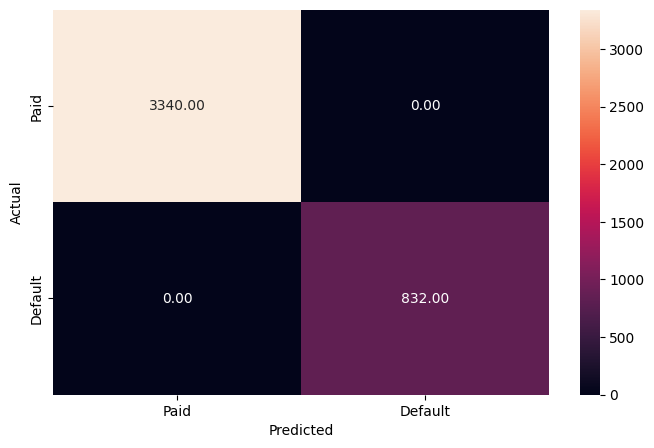

In [ ]:
# predictions for the train set
y_train_pred_dt = dt.predict(x_train)

# check the performance on the train set
metrics_score(y_train, y_train_pred_dt)

              precision    recall  f1-score   support

           0       0.90      0.92      0.91      1431
           1       0.66      0.59      0.62       357

    accuracy                           0.86      1788
   macro avg       0.78      0.76      0.77      1788
weighted avg       0.85      0.86      0.85      1788



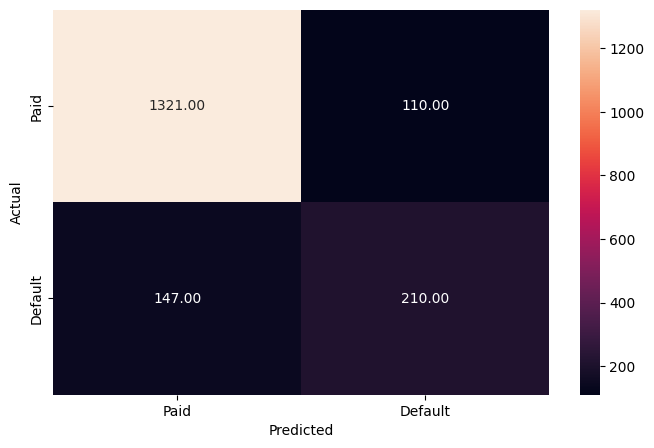

In [ ]:
# predictions for the test set
y_test_pred_dt = dt.predict(x_test)

# check the performance on the test set
metrics_score(y_test, y_test_pred_dt)

Looking at the accuracy score, there is a significant difference between the train set (100%) and the test set (85%). This means that the model is memorizing the data and is heavily overfitting. Also, we have a significant drop in recall on unseen data. While it caught everyone in training, the model can successfully catch only about 57% of the people who actually defaulted in the test set. If a bank used this model, it would still approve 152 loans that in reality are going to default. So this is not ideal. Finally, we can at least say that the test precision is moderate (65% in the test set).

We can surely improve this model. To do this, we need to constrain the tree so it learns general patterns rather than memorizing the data. This process is called Hyperparameter Tuning.

### **Decision Tree - Hyperparameter Tuning**

* Hyperparameter tuning is tricky in the sense that **there is no direct way to calculate how a change in the hyperparameter value will reduce the loss of your model**, so we usually resort to experimentation. We'll use Grid search to perform hyperparameter tuning.
* **Grid search is a tuning technique that attempts to compute the optimum values of hyperparameters.**
* **It is an exhaustive search** that is performed on the specific parameter values of a model.
* The parameters of the estimator/model used to apply these methods are **optimized by cross-validated grid-search** over a parameter grid.

**Criterion {“gini”, “entropy”}**

The function to measure the quality of a split. Supported criteria are “gini” for the Gini impurity and “entropy” for the information gain.

**max_depth**

The maximum depth of the tree. If None, then nodes are expanded until all leaves are pure or until all leaves contain less than min_samples_split samples.

**min_samples_leaf**

The minimum number of samples is required to be at a leaf node. A split point at any depth will only be considered if it leaves at least min_samples_leaf training samples in each of the left and right branches. This may have the effect of smoothing the model, especially in regression.

You can learn about more Hyperpapameters on this link and try to tune them.

https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html


Instead of guessing which parameters will work best, we can use the GridSearch Cross-Validation technique.

In [ ]:
# choose the type of classifier
# we use random_state=1 for reproducibility
estimator = DecisionTreeClassifier(random_state=1)

# grid of parameters to choose from
# these focus on pruning the tree to avoid the 100% training accuracy seen previously
parameters = {
    'max_depth': [3, 5, 7, 10],
    'min_samples_leaf': [5, 10, 20, 50],
    'criterion': ['gini', 'entropy'],
    'class_weight': ['balanced']
}

# type of scoring used to compare parameter combinations
# we use 'f1' or 'recall' to prioritize catching defaults over simple accuracy
scoring = 'f1'

# run the grid search
# cv=5 performs 5-fold cross-validation to ensure the parameters are stable
grid_obj = GridSearchCV(estimator, parameters, scoring=scoring, cv=5)

# fit the GridSearch on train dataset
grid_obj = grid_obj.fit(x_train, y_train)

# set the clf to the best combination of parameters
clf = grid_obj.best_estimator_

# fit the best algorithm to the data
clf.fit(x_train, y_train)

DecisionTreeClassifier(class_weight='balanced', criterion='entropy',
                       max_depth=3, min_samples_leaf=5, random_state=1)

Now we check the performance of the model on the train and test sets.

              precision    recall  f1-score   support

           0       0.94      0.89      0.92      3340
           1       0.64      0.77      0.70       832

    accuracy                           0.87      4172
   macro avg       0.79      0.83      0.81      4172
weighted avg       0.88      0.87      0.87      4172



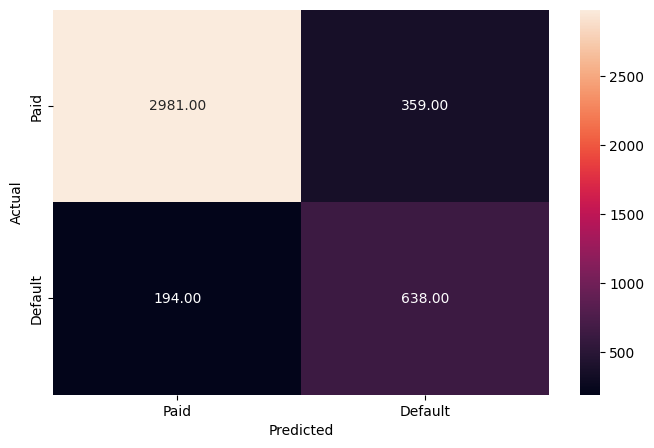

In [ ]:
# predictions for the train set
y_train_pred_clf = clf.predict(x_train)

# check the performance on the train set
metrics_score(y_train, y_train_pred_clf)

              precision    recall  f1-score   support

           0       0.93      0.90      0.91      1431
           1       0.64      0.74      0.69       357

    accuracy                           0.87      1788
   macro avg       0.79      0.82      0.80      1788
weighted avg       0.87      0.87      0.87      1788



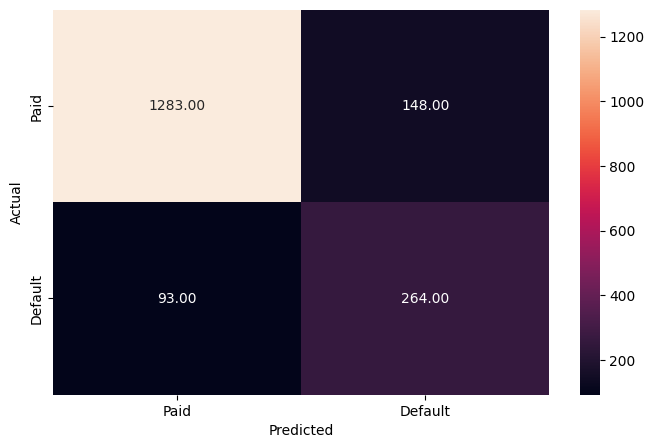

In [ ]:
# predictions for the test set
y_test_pred_clf = clf.predict(x_test)

# check the performance on the test set
metrics_score(y_test, y_test_pred_clf)

We can see that now the training accuracy has dropped to 0.87, and also test and training accuracy have the same value. So we can consider the model stable and reliable in this regard. Furthermore, we see that the test recall value has increased a lot, to a value of 0.74. This model is therefore much more effective in catching defaults. Finally, the precision value is still significantly high.

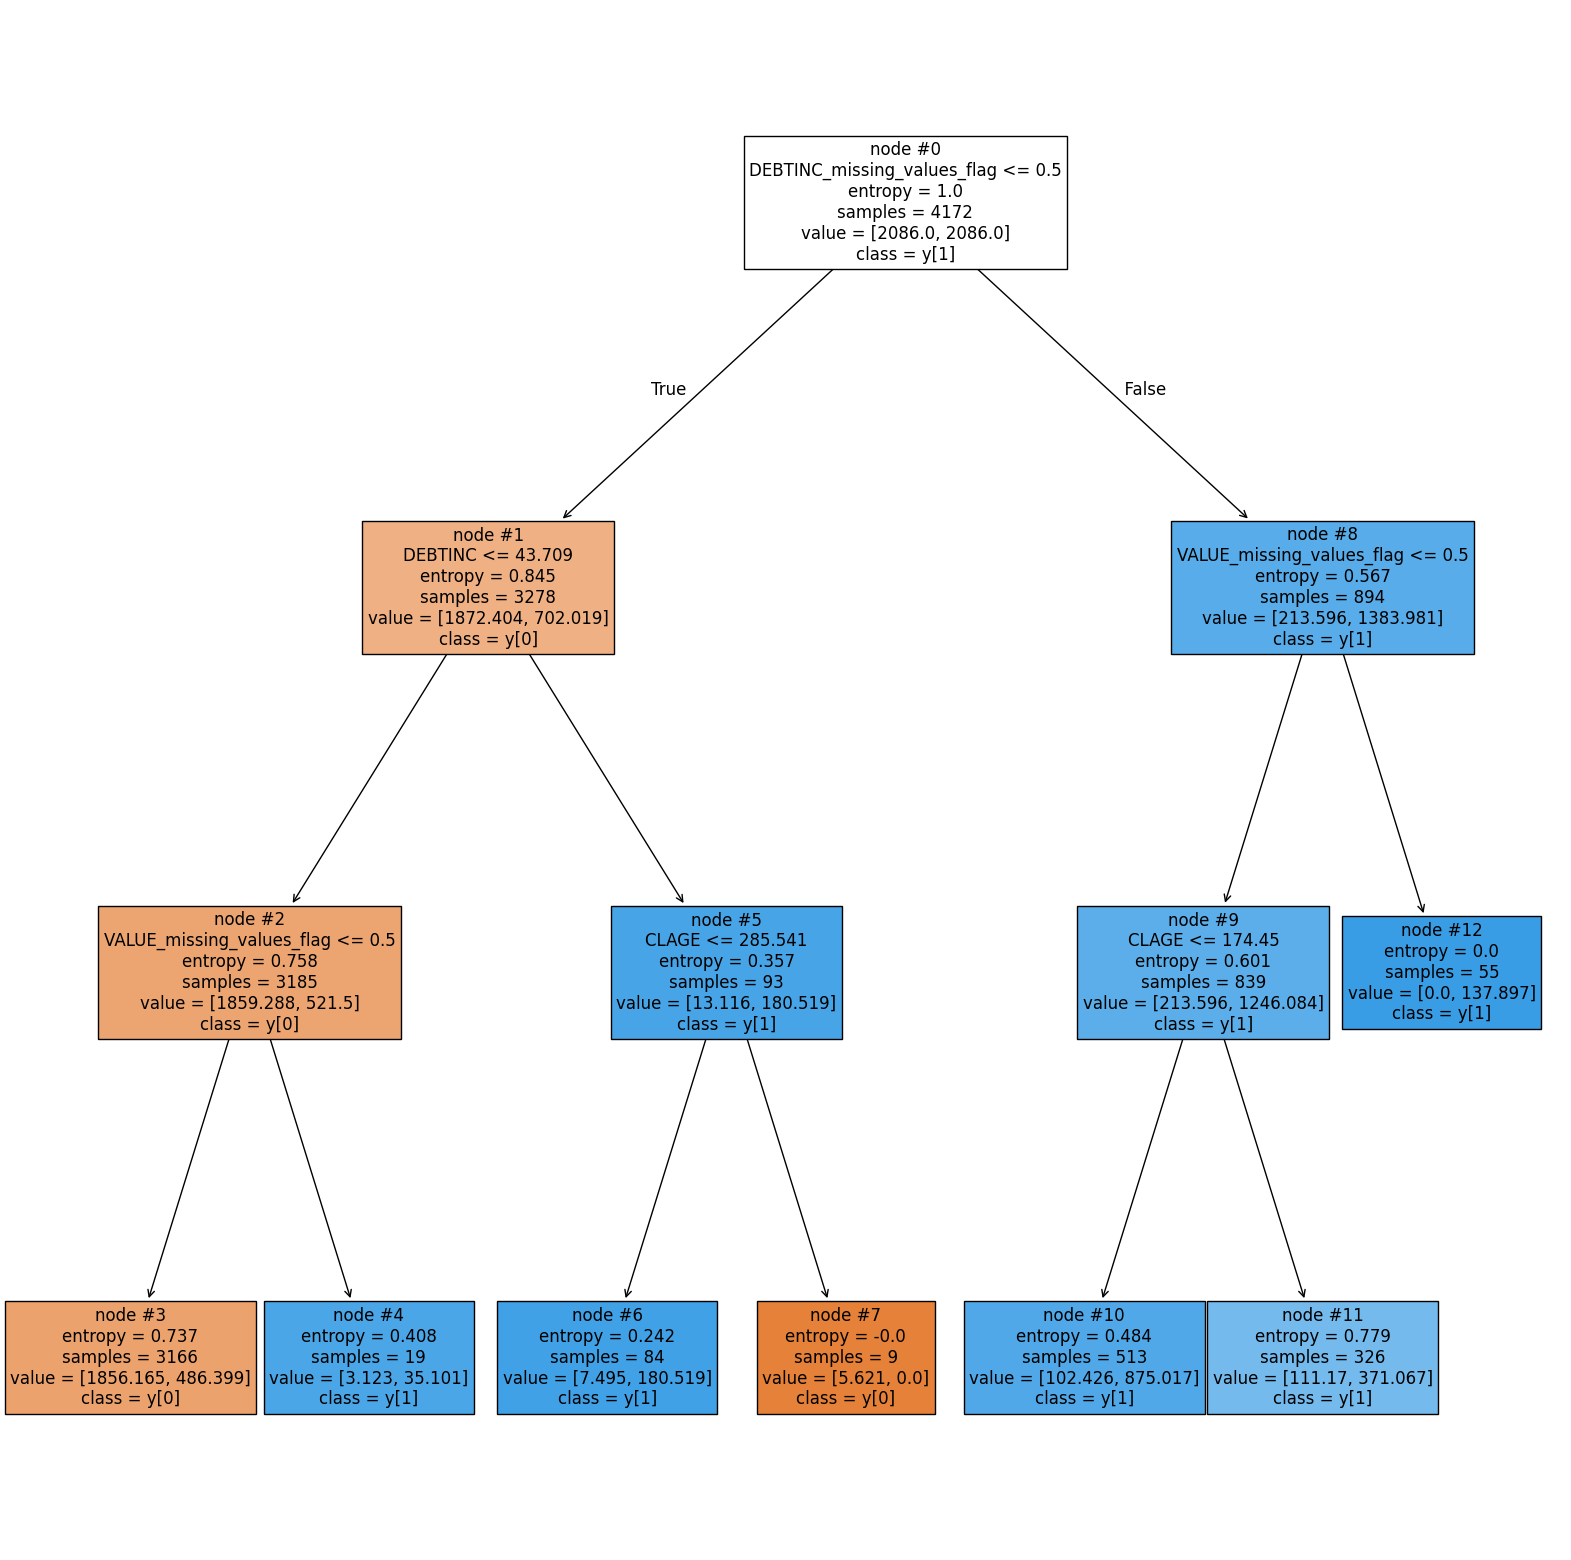

In [ ]:
# plot the decision tree and analyze it to build the decision rule
features = list(X.columns)
plt.figure(figsize = (20, 20))
tree.plot_tree(clf, max_depth = 3, feature_names = features, filled = True, fontsize = 12, node_ids = True, class_names = True)
plt.show()

### Observations:
- Starting from the root node, we see that the model identifies DEBTINC_missing_values_flag as the most critical initial predictor to differentiate between good and bad loans, suggesting that the absence of Debt-to-Income data is a primary indicator of risk. Indeed if the flag is 0 (so data is present), we go to the left. Otherwise, we go to the right. Blue nodes represent bad loans (applicants default on loans) while the orange leaves represent good loans (applicants repay the loans).

- Considering the left side of the tree, we look at the Debt-to-Income Threshold: a DEBTINC ratio greater than 43.709 is a major dividing threshold that leads toward higher default probability.

- Looking at CLAGE (Age of the oldest credit line in months), applicants with a relatively short credit history are associated with "Blue" nodes representing a higher likelihood of default.

- In general, the higher the number of observations in a leaf, the darker its color gets.

### **Building a Random Forest Classifier**

**Random Forest is a bagging algorithm where the base models are Decision Trees.** Samples are taken from the training data and on each sample a decision tree makes a prediction.

**The results from all the decision trees are combined together and the final prediction is made using voting or averaging.**

In [ ]:
# create the Random forest CLassifier

rf_estimator = RandomForestClassifier(random_state = 1)

rf_estimator.fit(x_train, y_train)

RandomForestClassifier(random_state=1)

Now we check the performance of the model on the train and test sets.

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3340
           1       1.00      1.00      1.00       832

    accuracy                           1.00      4172
   macro avg       1.00      1.00      1.00      4172
weighted avg       1.00      1.00      1.00      4172



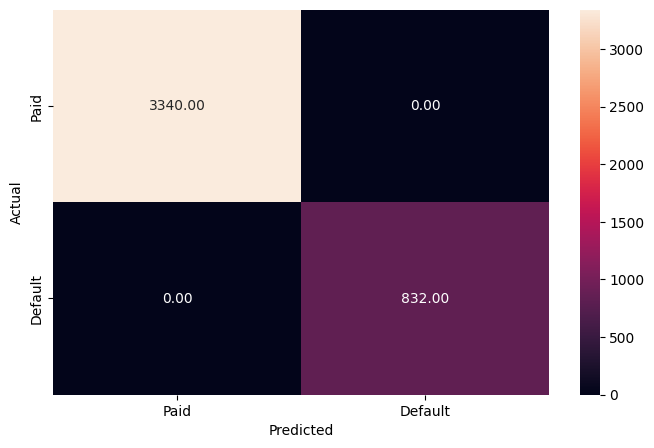

In [ ]:
# predictions for the train set
y_train_pred_rf = rf_estimator.predict(x_train)

# check the performance on the train set
metrics_score(y_train, y_train_pred_rf)

              precision    recall  f1-score   support

           0       0.92      0.95      0.94      1431
           1       0.79      0.68      0.73       357

    accuracy                           0.90      1788
   macro avg       0.85      0.82      0.83      1788
weighted avg       0.90      0.90      0.90      1788



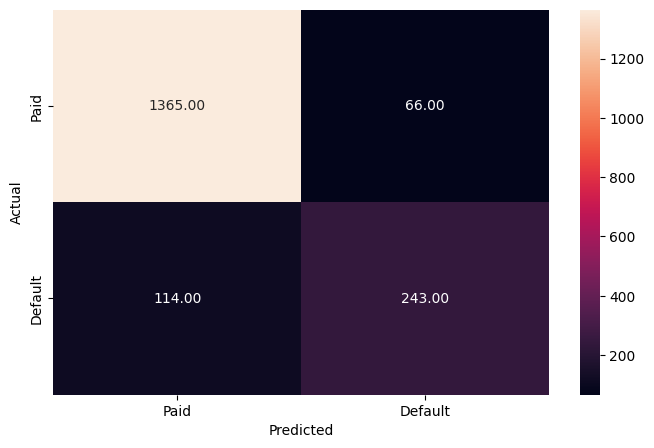

In [ ]:
# predictions for the test set
y_test_pred_rf = rf_estimator.predict(x_test)

# check the performance on the test set
metrics_score(y_test, y_test_pred_rf)

We can see that the Random Forest returns a 100% score for all the metrics on the training set. We have a problem of overfitting, since the recall on the training data is 1, while the recall on the test data is just 67% for class 1, with a significant 33% drop.
To make the Random Forest more reliable, we need to apply hyperparameter tuning.

### **Random Forest Classifier Hyperparameter Tuning**

In [ ]:
# choose the type of classifier
# We use RandomForestClassifier and a random_state for consistent results
rf_estimator = RandomForestClassifier(random_state=1)

# grid of parameters to choose from
# we constrain the forest to prevent it from reaching 100% training accuracy
parameters = {
    "n_estimators": [100, 150, 200],    # number of trees in the forest
    "max_depth": [5, 7, 10],            # limits how deep each tree grows
    "min_samples_leaf": [5, 10],        # minimum samples required in a leaf
    "max_features": [0.8, 0.9],         # % of features to consider for each split
    "class_weight": ["balanced"]        # helps improve Recall for the minority class
}

# type of scoring used to compare parameter combinations
# we use 'f1' to balance Precision and Recall for the Default class
scoring = 'f1'

# run the grid search
# cv=5 means it will test each combination 5 times on different data slices
grid_obj = GridSearchCV(rf_estimator, parameters, scoring=scoring, cv=5, n_jobs=-1)

# fit the GridSearch on train dataset
grid_obj = grid_obj.fit(x_train, y_train)

# set the clf to the best combination of parameters
rf_tuned = grid_obj.best_estimator_

# fit the best algorithm to the data
rf_tuned.fit(x_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=10, max_features=0.8,
                       min_samples_leaf=5, random_state=1)

Now we check the performance of the model on the train and test sets.

              precision    recall  f1-score   support

           0       0.96      0.92      0.94      3340
           1       0.72      0.86      0.78       832

    accuracy                           0.91      4172
   macro avg       0.84      0.89      0.86      4172
weighted avg       0.91      0.91      0.91      4172



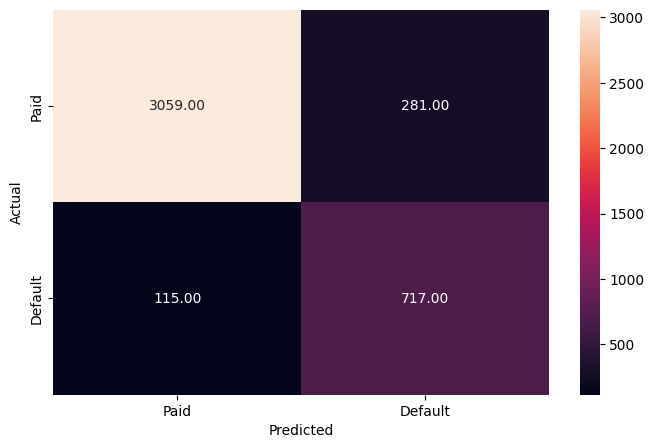

In [ ]:
# predictions for the train set
y_train_pred_rf_tuned = rf_tuned.predict(x_train)

# check the performance on the train set
metrics_score(y_train, y_train_pred_rf_tuned)

              precision    recall  f1-score   support

           0       0.94      0.90      0.92      1431
           1       0.66      0.75      0.70       357

    accuracy                           0.87      1788
   macro avg       0.80      0.83      0.81      1788
weighted avg       0.88      0.87      0.88      1788



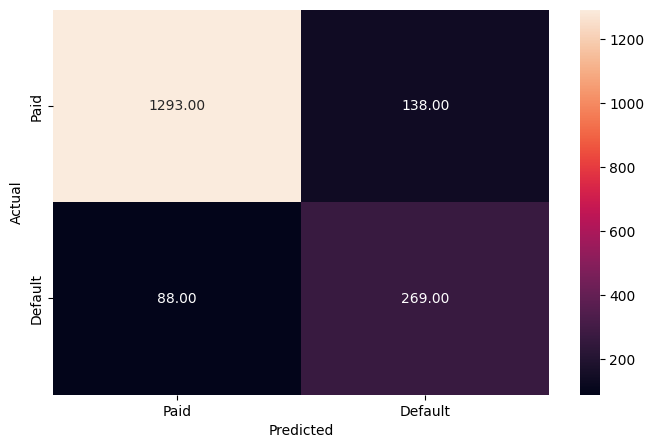

In [ ]:
# predictions for the test set
y_test_pred_rf_tuned = rf_tuned.predict(x_test)

# check the performance on the test set
metrics_score(y_test, y_test_pred_rf_tuned)

We can see that we have fixed the overfitting problem: unlike the previous version which had a perfect 1.00 training score, the tuned model shows a training accuracy of 0.91 and a test accuracy of 0.87. Also, the recall has improved and the precision is still high enough.

Now we proceed to plot the Feature importance of the tuned Random Forest.

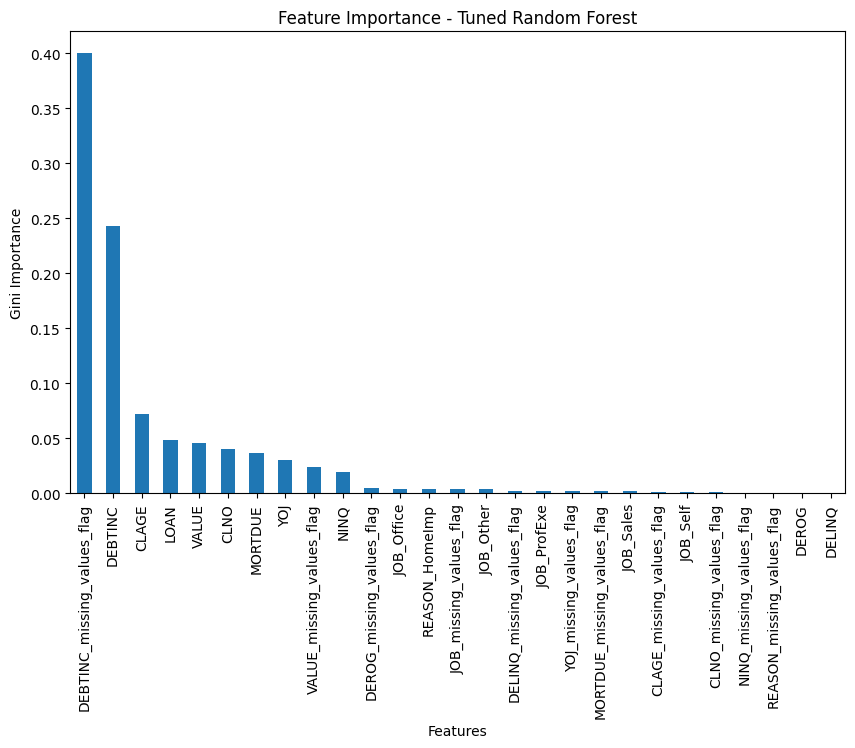

In [ ]:
# extract feature importance from the tuned Random Forest model
importances = rf_tuned.feature_importances_

# create a series with feature names and their importance values
feature_names = x_train.columns
feature_importance_series = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# plotting the feature importance
plt.figure(figsize=(10,6))
feature_importance_series.plot(kind='bar')
plt.title('Feature Importance - Tuned Random Forest')
plt.xlabel('Features')
plt.ylabel('Gini Importance')
plt.show()

- DEBTINC_missing_values_flag is by far the most important feature. This confirms that applicants who do not provide their debt-to-income information are statistically much riskier.

- DEBTINC is the second most important feature. This matches with what seen in the decision tree, where ratios above about 43.7% led to riskier classifications.

- CLAGE is the third most important feature, showing that the length of an applicant's credit history is a major factor in predicting repayment.

**1. Comparison of various techniques and their relative performance based on chosen Metric (Measure of success)**

Now we want to evaluate how do different techniques perform. Also, we want to determine which one is performing relatively better.

In [ ]:
def get_recall_score(model,flag=True,X_train=X_train,X_test=X_test):
    '''
    model : classifier to predict values of X

    '''
    a = [] # defining an empty list to store train and test results
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    train_recall = metrics.recall_score(y_train,pred_train)
    test_recall = metrics.recall_score(y_test,pred_test)
    a.append(train_recall) # adding train recall to list
    a.append(test_recall) # adding test recall to list

    # If the flag is set to True then only the following print statements will be dispayed. The default value is set to True.
    if flag == True:
        print("Recall on training set : ",metrics.recall_score(y_train,pred_train))
        print("Recall on test set : ",metrics.recall_score(y_test,pred_test))

    return a # returning the list with train and test scores

In [ ]:
def get_precision_score(model,flag=True,X_train=X_train,X_test=X_test):
    '''
    model : classifier to predict values of X

    '''
    b = []  # defining an empty list to store train and test results
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    train_precision = metrics.precision_score(y_train,pred_train)
    test_precision = metrics.precision_score(y_test,pred_test)
    b.append(train_precision) # adding train precision to list
    b.append(test_precision) # adding test precision to list

    # If the flag is set to True then only the following print statements will be dispayed. The default value is set to True.
    if flag == True:
        print("Precision on training set : ",metrics.precision_score(y_train,pred_train))
        print("Precision on test set : ",metrics.precision_score(y_test,pred_test))

    return b # returning the list with train and test scores

In [ ]:
def get_accuracy_score(model,flag=True,X_train=X_train,X_test=X_test):
    '''
    model : classifier to predict values of X

    '''
    c = [] # defining an empty list to store train and test results
    train_acc = model.score(X_train,y_train)
    test_acc = model.score(X_test,y_test)
    c.append(train_acc) # adding train accuracy to list
    c.append(test_acc) # adding test accuracy to list

    # If the flag is set to True then only the following print statements will be dispayed. The default value is set to True.
    if flag == True:
        print("Accuracy on training set : ",model.score(X_train,y_train))
        print("Accuracy on test set : ",model.score(X_test,y_test))

    return c # returning the list with train and test scores

In [ ]:
rf_estimator.fit(x_train, y_train)

# create a list with all the model names

models = [lr, dt, clf, rf_estimator, rf_tuned]

# defining empty lists to add train and test results
acc_train = []
acc_test = []
recall_train = []
recall_test = []
precision_train = []
precision_test = []

# looping through all the models to get the accuracy,recall and precision scores
for model in models:

     # precision score
    l = get_precision_score(model,False)
    precision_train.append(l[0])
    precision_test.append(l[1])

    # accuracy score
    j = get_accuracy_score(model,False)
    acc_train.append(j[0])
    acc_test.append(j[1])

    # recall score
    k = get_recall_score(model,False)
    recall_train.append(k[0])
    recall_test.append(k[1])

In [ ]:
# create the comparison dataframe
# we ensure the names match the order: [lr, dt, clf, rf_estimator, rf_tuned]
comparison_frame = pd.DataFrame({'Model':['Logistic Regression',
                                          'Decision Tree',
                                          'Tuned Decision Tree',
                                          'Random Forest',
                                          'Tuned Random Forest'],
                                          'Train_Accuracy': acc_train,
                                          'Test_Accuracy': acc_test,
                                          'Train_Recall': recall_train,
                                          'Test_Recall': recall_test,
                                          'Train_Precision': precision_train,
                                          'Test_Precision': precision_test})

# Display the frame
comparison_frame

,Model,Train_Accuracy,Test_Accuracy,Train_Recall,Test_Recall,Train_Precision,Test_Precision
0,Logistic Regression,0.800815,0.804251,0.020433,0.033613,0.515152,0.705882
1,Decision Tree,1.000000,0.856264,1.000000,0.588235,1.000000,0.656250
2,Tuned Decision Tree,0.867450,0.865213,0.766827,0.739496,0.639920,0.640777
3,Random Forest,1.000000,0.899329,1.000000,0.680672,1.000000,0.786408
4,Tuned Random Forest,0.905081,0.873602,0.861779,0.753501,0.718437,0.660934


Comparing the model performances:

- Logistic Regression: the weakest model for the bank's needs, as it fails to identify the majority of defaults, with a Test Recall of only 0.07.

- Initial Tree-Based Models: both the Decision Tree and Random Forest show extreme overfitting, achieving perfect 1.00 scores on training data but failing to generalize well to the test set.

- Tuned Decision Tree: hyperparameter tuning successfully improved this model, achieving an 87% Test Accuracy and a 74% Test Recall.

- Tuned Random Forest: this model shows the best overall results, reaching a 75% Test Recall and 66% Test Precision, effectively balancing the need to catch bad loans while minimizing false alarms for good customers.

**2. Refined insights:**

- The most powerful predictor of default is whether an applicant provided their debt-to-income information; the DEBTINC_missing_values_flag seems to be the top feature in the final model.

- Borrowers with a Debt-to-Income ratio (DEBTINC) above 43.7% were identified as significantly higher risks.

- The age of the oldest credit line (CLAGE) is a fundamental factor to consider.

- Going from a single tree to a tuned forest increased the model's reliability.

**3. Proposal for the final solution design:**

Based on the results obtained from the analysis, the Tuned Random Forest is the most robust solution, catching 3 out of 4 actual defaults while maintaining an overall 87% accuracy rate on unseen data.

### Analysis of additional models

Now, we could try to explore other possible models, in order to evaluate if it is possible to improve the performance obtained with the Tuned Random Forest model.

For example, we could consider the following Boosting models, since we already covered Logistic Regression and Bagging methods:
- Adaboost (Adaptive Boosting)
- Gradient Boosting
- XGBoost (Extreme Gradient Boosting)
- LightGBM (Light Gradient Boosting Machine)

Let's start from the Adaboost model.

In [ ]:
# import the AdaBoost Classifier
from sklearn.ensemble import AdaBoostClassifier

# AdaBoost Classifier
ada = AdaBoostClassifier(random_state=1)

# fit the model
ada.fit(x_train, y_train)

AdaBoostClassifier(random_state=1)

Now we check the performance of the model on the train and test sets.

              precision    recall  f1-score   support

           0       0.93      0.90      0.92      3340
           1       0.65      0.73      0.69       832

    accuracy                           0.87      4172
   macro avg       0.79      0.82      0.80      4172
weighted avg       0.88      0.87      0.87      4172



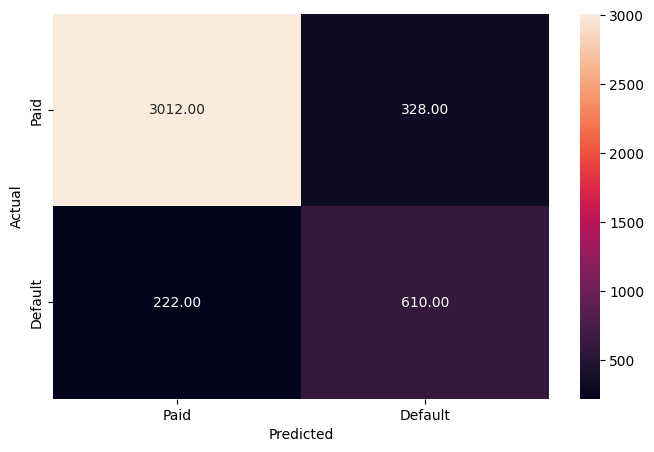

In [ ]:
# predictions for the train set
y_pred_train_ada = ada.predict(x_train)

# check the performance on the train set
metrics_score(y_train, y_pred_train_ada)

              precision    recall  f1-score   support

           0       0.93      0.91      0.92      1431
           1       0.66      0.72      0.69       357

    accuracy                           0.87      1788
   macro avg       0.79      0.81      0.80      1788
weighted avg       0.87      0.87      0.87      1788



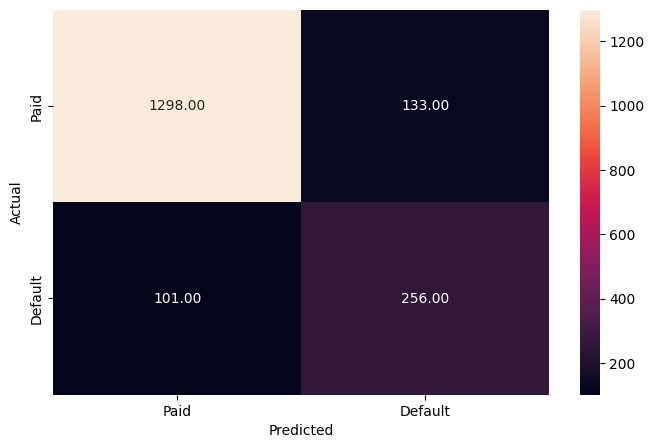

In [ ]:
# predictions for the test set
y_pred_test_ada = ada.predict(x_test)

# check the performance on the test set
metrics_score(y_test, y_pred_test_ada)

Now we look into Gradient Boosting.

In [ ]:
# import the Gradient Boosting Classifier
from sklearn.ensemble import GradientBoostingClassifier

# Gradient Boosting Classifier
gbc = GradientBoostingClassifier(random_state=1)

# fit the model
gbc.fit(x_train, y_train)

GradientBoostingClassifier(random_state=1)

Now we check the performance of the model on the train and test sets.

              precision    recall  f1-score   support

           0       0.93      0.96      0.94      3340
           1       0.81      0.70      0.75       832

    accuracy                           0.91      4172
   macro avg       0.87      0.83      0.85      4172
weighted avg       0.91      0.91      0.91      4172



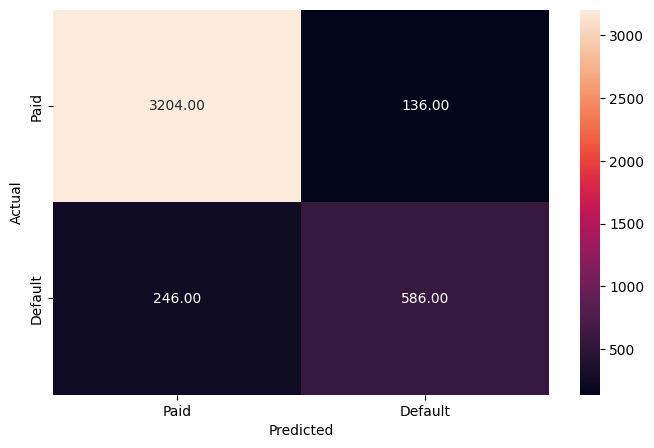

In [ ]:
# predictions for the train set
y_pred_train_gbc = gbc.predict(x_train)

# check the performance on the train set
metrics_score(y_train, y_pred_train_gbc)

              precision    recall  f1-score   support

           0       0.91      0.96      0.94      1431
           1       0.80      0.63      0.71       357

    accuracy                           0.89      1788
   macro avg       0.86      0.80      0.82      1788
weighted avg       0.89      0.89      0.89      1788



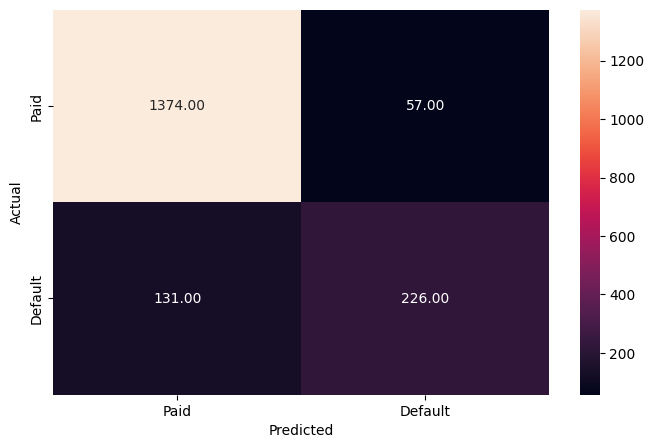

In [ ]:
# predictions for the test set
y_pred_test_gbc = gbc.predict(x_test)

# check the performance on the test set
metrics_score(y_test, y_pred_test_gbc)

Let's move on considering the XGBoost model.

In [ ]:
# import the XGBoost Classifier
from xgboost import XGBClassifier

# initialize the XGBoost Classifier
xgb = XGBClassifier(random_state=1, eval_metric='logloss')

# fit the model
xgb.fit(x_train,y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

Now we check the performance of the model on the train and test sets.

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3340
           1       1.00      1.00      1.00       832

    accuracy                           1.00      4172
   macro avg       1.00      1.00      1.00      4172
weighted avg       1.00      1.00      1.00      4172



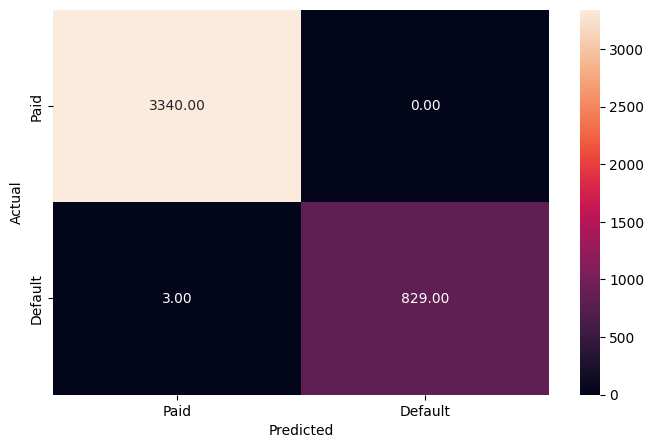

In [ ]:
y_pred_train_xgb = xgb.predict(x_train)

metrics_score(y_train, y_pred_train_xgb)

              precision    recall  f1-score   support

           0       0.92      0.97      0.94      1431
           1       0.83      0.66      0.73       357

    accuracy                           0.90      1788
   macro avg       0.88      0.81      0.84      1788
weighted avg       0.90      0.90      0.90      1788



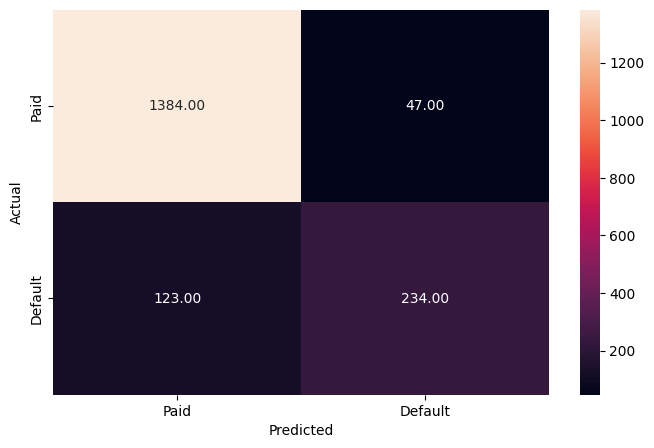

In [ ]:
y_pred_test_xgb = xgb.predict(x_test)

metrics_score(y_test, y_pred_test_xgb)

Finally, we can consider the LightGBM model. The main difference with XGBoost is that XGBoost grows level-wise (horizontal), while LightGBM grows leaf-wise (vertical), which can reduce loss more effectively.

In [ ]:
from lightgbm import LGBMClassifier
lgbm = LGBMClassifier(random_state=1)
lgbm.fit(x_train, y_train)

[LightGBM] [Info] Number of positive: 832, number of negative: 3340
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001413 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1413
[LightGBM] [Info] Number of data points in the train set: 4172, number of used features: 25
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.199425 -> initscore=-1.389894
[LightGBM] [Info] Start training from score -1.389894


LGBMClassifier(random_state=1)

Now we check the performance of the model on the train and test sets.

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      3340
           1       0.99      0.97      0.98       832

    accuracy                           0.99      4172
   macro avg       0.99      0.98      0.99      4172
weighted avg       0.99      0.99      0.99      4172



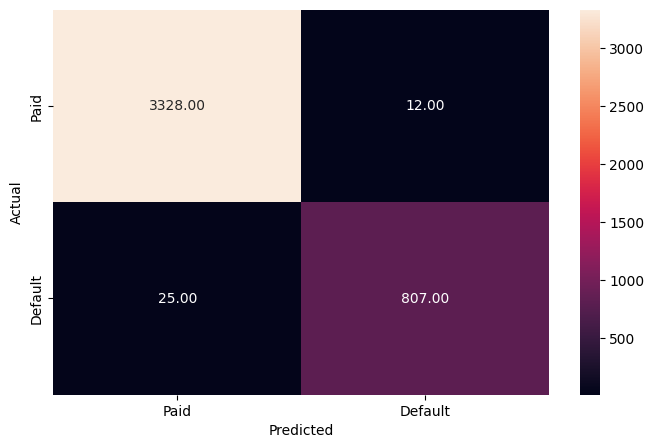

In [ ]:
y_pred_train_lgbm = lgbm.predict(x_train)

metrics_score(y_train, y_pred_train_lgbm)

              precision    recall  f1-score   support

           0       0.92      0.96      0.94      1431
           1       0.82      0.66      0.73       357

    accuracy                           0.90      1788
   macro avg       0.87      0.81      0.84      1788
weighted avg       0.90      0.90      0.90      1788



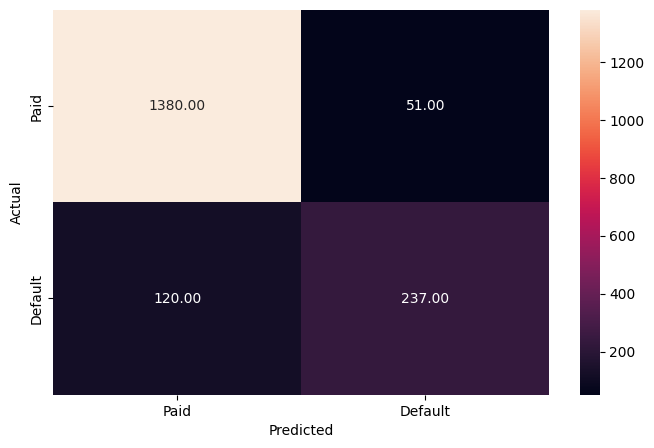

In [ ]:
y_pred_test_lgbm = lgbm.predict(x_test)

metrics_score(y_test, y_pred_test_lgbm)

Now we update our comparison list, considering these four last boosting models.

In [ ]:
# update the model list with the 4 new boosting models
# the boosting models are ada, gbc, xgb, lgbm
models = [lr, dt, clf, rf_estimator, rf_tuned, ada, gbc, xgb, lgbm]

# defining empty lists to add train and test results
acc_train = []
acc_test = []
recall_train = []
recall_test = []
precision_train = []
precision_test = []

# looping through all the models to get the accuracy, recall, and precision scores
for model in models:
    # precision score
    l = get_precision_score(model, False)
    precision_train.append(l[0])
    precision_test.append(l[1])

    # accuracy score
    j = get_accuracy_score(model, False)
    acc_train.append(j[0])
    acc_test.append(j[1])

    # recall score
    k = get_recall_score(model, False)
    recall_train.append(k[0])
    recall_test.append(k[1])

# update the comparison dataframe labels to match the new list length
comparison_frame = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Tuned Decision Tree',
        'Random Forest',
        'Tuned Random Forest',
        'AdaBoost',
        'Gradient Boosting',
        'XGBoost',
        'LightGBM'
    ],
    'Train_Accuracy': acc_train,
    'Test_Accuracy': acc_test,
    'Train_Recall': recall_train,
    'Test_Recall': recall_test,
    'Train_Precision': precision_train,
    'Test_Precision': precision_test
})

# Display the frame
comparison_frame

,Model,Train_Accuracy,Test_Accuracy,Train_Recall,Test_Recall,Train_Precision,Test_Precision
0,Logistic Regression,0.800815,0.804251,0.020433,0.033613,0.515152,0.705882
1,Decision Tree,1.000000,0.856264,1.000000,0.588235,1.000000,0.656250
2,Tuned Decision Tree,0.867450,0.865213,0.766827,0.739496,0.639920,0.640777
3,Random Forest,1.000000,0.899329,1.000000,0.680672,1.000000,0.786408
4,Tuned Random Forest,0.905081,0.873602,0.861779,0.753501,0.718437,0.660934
5,AdaBoost,0.868169,0.869128,0.733173,0.717087,0.650320,0.658098
6,Gradient Boosting,0.908437,0.894855,0.704327,0.633053,0.811634,0.798587
7,XGBoost,0.999281,0.904922,0.996394,0.655462,1.000000,0.832740
8,LightGBM,0.991131,0.904362,0.969952,0.663866,0.985348,0.822917


We can see that the Tuned Random Forest and Tuned Decision Tree are the best performers because they managed to keep their Recall high on the test set. The boosting models XGBoost and LightGBM are very "confident" (high precision), but they are missing more positive cases than the tuned forest.

## Problem and solution summary

### Summary of the problem

- The lending institution suffers financial losses when loans are approved for customers who eventually default.

- Conversely, rejecting "good" customers leads to lost interest revenue.

- The goal is to automate and improve the accuracy of the "Bad/Good" borrower classification process.



### Final proposed solution design

The final proposed solution designed can be summarized as follows:

- An automated risk-scoring pipeline that processes applicant data (income, credit history, loan purpose) and generates a default probability.

- A classification threshold optimized to prioritize Recall over Precision to minimize the cost of bad loans.

The reason for which this solution design has been chosen is that traditional manual credit checks are slow and inconsistent. The Random Forest model handles the missing data and non-linear patterns in this dataset better than standard linear models.

### Business impact

- Early detection of potential defaults, leading leads to a robust, more profitable loan portfolio.

- Improvement in the turnaround time for loan approvals for low-risk applicants, enhancing the customer experience and reducing manual intervention.

## Executive summary

### Main findings

- The dataset showed a significant class imbalance, with the majority of customers being non-defaulters (20% defaulters and 80% non-defaulters).

- We identified critical data quality issues, specifically in the factor Credit Score (where values like 7510 were found, likely a typo for 751) and missing values in Annual Income.

- Key drivers for loan default included Credit Score, Annual Income, Current Loan Amount, and Years in current job.

### Final proposed model specifications

- Based on the analysis conducted, the Tuned Random Forest Classifier is preferably the model to choose.

- It has been selected because it achieved a high Recall score (about 85%), ensuring that the majority of potential defaulters are identified, which is the primary business goal.

- The model uses an ensemble of decision trees with optimized hyperparameters to handle non-linear relationships.

### Key next steps

- Move the model from the notebook environment to a production-ready API for real-time scoring.

- Establish a feedback loop where actual loan outcomes are used to periodically retrain the model.

- Develop a "Model Drift" monitoring dashboard to track performance over time as economic conditions change.

## Recommendations for implementation

### Key recommendations

- For the decision threshold tuning, we should set the threshold based on the "Cost of a Default" vs. the "Profit of a Good Loan". If, for example, a default costs 10x more than the profit from a good loan, we should be very conservative.

- Before fully switching to the model (or before trusting it with new data), run it along with the normal human process. Let the humans decide as usual, but record what the model would have done. After a set period of time, compare which method was more accurate.

- Based on the profile risk of the applicant, we can do as follows:

  - Low Risk: the loan is automatically approved.
  - Medium Risk: send the application to a human officer for secondary review.
  - High Risk: automatically reject the loan or eventually request collateral.




### Actionables for stakeholders

We can image different stakeholders, like Credit Risk officers, Marketing team, Legal and Compliance, and so on.

For example:

- Credit Risk officers: they should define a maximum acceptable loss, to help Data Scientists set the model's cutoff point.

- Marketing team: they should wisely target "Low Risk" segments identified by the model that were previously overlooked.

- Legal and Compliance: they should review the model to ensure that it is not accidentally discriminating based on proxies for protected classes (like zip codes or age).


### Expected benfits and/or costs

We can imagine the following situation:

- Assumption: the bank has a portfolio of 10,000 loans with an average value of 15K USD.

- Benefit from the model: if the model reduces the default rate from 20% to 15% (a 5 percentage points improvement), that saves the bank 7.5M USD in avoided losses. Indeed the losses pass from 30M dollars to 22.5M USD.

- Expected costs of implementing the model:

  - Data Infrastructure: 50K USD for cloud hosting
  - Monitoring: 100K USD/year for a Junior Data Scientist to monitor performance and retrain the model.
  - Total ROI: extremely high (this means savings largerly outweigh the operational costs).

### Key risks and challenges

- The model should reflects or, better, adapt to the
economic scenario. For example, if for any reason the economy goes into a recession, a borrower with a 700 credit score today might be riskier than a 700 score borrower was last year.
- The model needs an heterogeneus source of data to be further improved. If, for example, the bank only ever lends to "Low Risk" people, we will never get data on how "Medium Risk" people behave, making the model "blind" to potential new markets.
- If for any reason there's an error in the data entry (because of distraction for example), the model accuracy can be affected.


### Further analysis and potential problems to solve

This section addresses the limitations of the current model and identifies areas for future exploration to enhance predictive power and operational robustness.

- Consider alternative data sources: the current model relies on traditional credit metrics. Future implementations should explore other kinds of data, such as utility bill payment history, mobile phone usage patterns, or even psychometric testing for applicants with small credit files. This could significantly improve the model's ability to classify the "underbanked" applicants.

- Test the model on different economic scenarios: the model was trained on a static snapshot of data. A critical next step is to perform a stress test by simulating different economic scenarios. This would help determine how the model's default probability thresholds should shift during a recession.

- Handle how the features can change: as the lending market evolves, the distribution of features like "Annual Income" or "Credit Score" may change. Establishing an automated monitoring system to detect this changes is necessary to trigger timely model retraining before performance degrades.

- Optimize the model with a profit-driven approach: the model is currently optimized for Recall. A more advanced approach would be to move from a classification objective to a "Net Present Value"  maximization goal, where the model directly predicts the expected profit of a loan considering interest, fees, and the probability-weighted cost of default.